# Project 13 — Hybrid Quantum-Classical Cloud Computing Platform
**Level:** Advanced · **Named library:** Qiskit (used *only* in the final cross-check) · **Core:** NumPy + stdlib, in-process.

## Why this notebook is built the way it is
A notebook cannot open a network socket, hold a cloud credential, or write a file. So we do not
fake a cloud with `print()` statements: we build the **real** object model of a hybrid
quantum-classical platform — client SDK, request queue, scheduler/worker pool, job store,
result storage, cost accounting — as ordinary Python classes and dataclasses, and put the single
I/O-shaped seam exactly where the cloud seam is in production: the `BackendAdapter` interface.

Everything above that seam is real code doing real work. Everything below it is one of three
interchangeable adapters:

| Adapter | What it really does | What it stands in for |
|---|---|---|
| `LocalStatevector` | our from-scratch NumPy simulator; exact amplitudes **and** shot-based counts | a self-hosted simulator node / `Braket.LocalSimulator` |
| `QiskitBasicAdapter` | wraps `qiskit.providers.basic_provider.BasicSimulator`, skipped if qiskit is absent | a vendor SDK shipped as a wheel |
| `MockRemoteAdapter` | deterministic latency, queue-depth delay, throttling, retryable failures, multinomial shot noise, **no** statevector channel | AWS Braket / Azure Quantum / GCP-backed QPU |

`MockRemoteAdapter` is deliberately *not* allowed to return amplitudes: on real hardware you buy
`shots`, you do not get the wavefunction. That asymmetry forces the classical optimiser to work
with noisy expectation values, which is the actual engineering problem a hybrid platform solves.

## What you get
1. A gate IR + statevector simulator + multinomial sampler, cross-checked against an independent
   dense-matrix path; the max deviation is printed in Part 10a and is bit-exact (0.000e+00) on
   every circuit run here.
2. A job lifecycle `submit -> queued -> running -> done/failed/cancelled` with monotonic ids,
   idempotency keys, retries, and **real** threads guarded by a lock (plus a deterministic
   discrete-event scheduler for latency sweeps).
3. A VQE loop whose gradients and energies are requested **through the platform API**, never by
   calling the simulator directly.
4. Job store, cost model, and 6 measured figures (two of them two-panel): throughput, p50/p95
   latency, retries, cost, scaling with qubits/depth, sampling convergence, convergence curves.
5. 150+ self-tests with measured tolerances, then a Qiskit cross-check.

## Part 1 — Architecture and the seams that map to a real provider

```
 user code
    |
    v
 QuantumClient (SDK)      submit / get_job / result / wait / cancel / expectation
    |  JobRequest                                         JobRecord + BackendResult
    v                                                        ^
 InProcessQueue  ->  Scheduler (ThreadPoolExecutor, lock)  ->  JobStore (dict + lock)
                                                                   |
                                                        BackendAdapter (THE seam)
                                        LocalStatevector | QiskitBasicAdapter | MockRemoteAdapter
```

| Our object | One-line responsibility | AWS Braket | Azure Quantum | GCP (Quantum Engine via Qiskit) |
|---|---|---|---|---|
| `QuantumClient.submit()` | hand a circuit + shots to a queue, return a job id | `AwsQuantumTask.create(...)` / `braket.tasks` | `qmi.jobs.create` / `qdk.QioJob.create` | `engine.run_(circuit)` -> `Job` |
| `JobRecord` | id, status, timestamps, attempts | `AwsQuantumTask` ARN + `state()` | job id + `status` | `job.status()` |
| `JobStore` | in-memory result table | S3 object under the task bucket | Blob container | GCS object |
| `BackendAdapter.run()` | execute on a device, return counts | `Device` (QPU/simulator ARN) | target id `ibm_q_...`, `quantinuum_...` | processor name |
| `CostModel` | price per shot | on-demand `$`/shot | executions/hourly metering | per-QPU-second |
| hybrid loop | optimiser asks platform for `<H>` | `AnnealingQuantumProgram`/`GateModelQuantumProgram` + classical loop you host | `qdk` Python on a VM | your own VM + Engine |

The next cell builds the execution engine. Note the discipline: **nothing here knows about jobs,
queues or the cloud.** The layering is enforced by what each cell is allowed to import.

In [1]:
import numpy as np, math, cmath, time, threading, itertools, hashlib
import collections, concurrent.futures, abc, random
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Callable

np.random.seed(0)
T0 = time.perf_counter()
MEASURED = {}          # numbers we print now become the tolerances we assert later

# ---------------------------------------------------------------- gate IR
@dataclass(frozen=True)
class Gate:
    """The whole circuit description language: (q, name, params, targets)."""
    name: str
    targets: Tuple[int, ...]
    params: Tuple[float, ...] = ()

# ---------------------------------------------------------------- 1q/2q matrices
_I2 = np.eye(2, dtype=complex)
_P0 = np.array([[1, 0], [0, 0]], dtype=complex)
_P1 = np.array([[0, 0], [0, 1]], dtype=complex)
_X = np.array([[0, 1], [1, 0]], dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.array([[1, 0], [0, -1]], dtype=complex)
_Hm = np.array([[1, 1], [1, -1]], dtype=complex) / math.sqrt(2.0)
_S = np.array([[1, 0], [0, 1j]], dtype=complex)
_T = np.array([[1, 0], [0, cmath.exp(1j * math.pi / 4)]], dtype=complex)

def _rot(P, t):
    """exp(-i t P / 2) for a Pauli P: cos(t/2) I - i sin(t/2) P."""
    return math.cos(t / 2.0) * _I2 - 1j * math.sin(t / 2.0) * P

ONE_Q = {"h": _Hm, "x": _X, "y": _Y, "z": _Z, "s": _S, "t": _T,
         "sdg": _S.conj().T, "tdg": _T.conj().T}
TWO_Q = {"cx": np.kron(_P0, _I2) + np.kron(_P1, _X),
         "cz": np.kron(_P0, _I2) + np.kron(_P1, _Z),
         "swap": np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], dtype=complex)}

class SimulatorError(ValueError):
    pass

def gate_matrix(name, params=()):
    if name in ONE_Q:
        if params: raise SimulatorError("%s takes no params" % name)
        return ONE_Q[name]
    if name in ("rx", "ry", "rz"):
        if len(params) != 1: raise SimulatorError(name + " needs 1 param")
        return _rot({"rx": _X, "ry": _Y, "rz": _Z}[name], params[0])
    if name in TWO_Q:
        if params: raise SimulatorError("%s takes no params" % name)
        return TWO_Q[name]
    if name == "crz":
        c, s = math.cos(params[0] / 2.0), math.sin(params[0] / 2.0)
        return np.array([[1, 0, 0, 0], [0, 1, 0, 0],
                         [0, 0, c, -1j * s], [0, 0, -1j * s, c]], dtype=complex)
    raise SimulatorError("unknown gate: " + name)

# ---------------------------------------------------------------- circuit
@dataclass
class Circuit:
    n: int
    gates: List[Gate] = field(default_factory=list)

    def g(self, name, targets, params=()):
        for q in targets:
            if not (0 <= q < self.n): raise SimulatorError("qubit %d out of range" % q)
        k = 2 if name in TWO_Q or name == "crz" else 1
        if len(targets) != k: raise SimulatorError("%s is %dq" % (name, k))
        if len(set(targets)) != k: raise SimulatorError("duplicate target")
        gate_matrix(name, params)                    # validate now, not at execution time
        self.gates.append(Gate(name, tuple(targets), tuple(float(p) for p in params)))
        return self

    def h(self, q):  return self.g("h", (q,))
    def x(self, q):  return self.g("x", (q,))
    def y(self, q):  return self.g("y", (q,))
    def z(self, q):  return self.g("z", (q,))
    def s(self, q):  return self.g("s", (q,))
    def t(self, q):  return self.g("t", (q,))
    def cx(self, c, t): return self.g("cx", (c, t))
    def cz(self, c, t): return self.g("cz", (c, t))
    def swap(self, a, b): return self.g("swap", (a, b))
    def crz(self, c, t, th): return self.g("crz", (c, t), (th,))
    def rx(self, q, t): return self.g("rx", (q,), (t,))
    def ry(self, q, t): return self.g("ry", (q,), (t,))
    def rz(self, q, t): return self.g("rz", (q,), (t,))

    def ir(self):
        """Explicit intermediate representation tuples (q, name, params, targets)."""
        return [(self.n, gt.name, gt.params, gt.targets) for gt in self.gates]

    def inverse(self):
        """Dagger in reverse order -- used to prove our simulator is unitary."""
        inv_name = {"s": "sdg", "sdg": "s", "t": "tdg", "tdg": "t"}
        out = Circuit(self.n)
        for gt in reversed(self.gates):
            if gt.name in ("rx", "ry", "rz", "crz"):
                out.g(gt.name, gt.targets, tuple(-p for p in gt.params))
            elif gt.name in inv_name:
                out.g(inv_name[gt.name], gt.targets)
            elif gt.name in ONE_Q or gt.name in TWO_Q:
                out.g(gt.name, gt.targets)          # h, x, y, z, cx, cz, swap are self-inverse
            else:
                raise SimulatorError("no inverse for " + gt.name)
        return out

    def depth(self):
        layer = [0] * self.n
        for gt in self.gates:
            m = max(layer[q] for q in gt.targets) + 1
            for q in gt.targets: layer[q] = m
        return max(layer) if layer else 0

    def copy(self):
        return Circuit(self.n, list(self.gates))

# ---------------------------------------------------------------- engine (tensor contraction)
def apply_gate(psi, mat, targets, n):
    t = psi.reshape([2] * n)
    k = len(targets)
    mt = np.asarray(mat, dtype=complex).reshape([2] * k + [2] * k)
    out = np.tensordot(mt, t, axes=(list(range(k, 2 * k)), list(targets)))
    rest = [q for q in range(n) if q not in targets]
    perm = [0] * n
    for j, q in enumerate(targets): perm[q] = j
    for j, q in enumerate(rest):   perm[q] = k + j
    return np.transpose(out, perm).reshape(2 ** n)

def statevector(circ):
    psi = np.zeros(2 ** circ.n, dtype=complex); psi[0] = 1.0
    for gt in circ.gates:
        psi = apply_gate(psi, gate_matrix(gt.name, gt.params), gt.targets, circ.n)
    return psi

def probabilities(circ):
    psi = statevector(circ)
    p = np.abs(psi) ** 2
    return p / p.sum()

print("gate inventory:", sorted(ONE_Q), sorted(TWO_Q), "+ rx/ry/rz/crz")
demo = Circuit(3).h(0).cx(0, 1).cz(1, 2).rx(2, 0.7).h(1)
print("demo IR first tuples:", demo.ir()[:3])
print("demo depth =", demo.depth(), "gates =", len(demo.gates))
print("demo |psi| first 4 amps:", np.round(statevector(demo)[:4], 6).tolist())
print("demo probs sum:", float(probabilities(demo).sum()))

gate inventory: ['h', 's', 'sdg', 't', 'tdg', 'x', 'y', 'z'] ['cx', 'cz', 'swap'] + rx/ry/rz/crz
demo IR first tuples: [(3, 'h', (), (0,)), (3, 'cx', (), (0, 1)), (3, 'cz', (), (1, 2))]
demo depth = 4 gates = 5
demo |psi| first 4 amps: [(0.469686+0j), -0.171449j, (0.469686+0j), -0.171449j]
demo probs sum: 1.0


## Measurement conventions (read this before the numbers)

**Endianness.** Our statevector is indexed `i = sum_j b_j 2^(n-1-j)`, i.e. **qubit 0 is the most
significant bit** ("big-endian", the textbook `|b_0 b_1 ... b_{n-1}>` convention). Bitstring labels
follow the same order, so `"100"` means qubit 0 is `1`. Qiskit prints counts with **qubit 0 on the
right** (little-endian creg string). The two differ by a reversal of the string, and we handle that
explicitly in the Qiskit cross-check rather than hoping the reader notices.

**Shots.** Exact amplitudes are a *simulator-only* luxury. Device output is a multinomial draw
`counts ~ Multinomial(shots, p)` with `p = |psi|^2`, so frequencies carry `O(1/sqrt(shots))`
noise and a 50/50 qubit will *never* report exactly 0.5. We quantify that with a Hoeffding bound
later instead of hand-waving it.

**Determinism.** Every stochastic draw takes an explicit `seed` derived from the job id, so a
retried job with a fixed seed reproduces bit-for-bit and a retried job without one does not.

In [2]:
# ---------------------------------------------------------------- bitstrings + sampling
def bitstring(i, n):
    """Big-endian label: qubit 0 is the leftmost character."""
    return "".join("1" if (i >> (n - 1 - j)) & 1 else "0" for j in range(n))

def index_of(bits):
    n = len(bits)
    i = 0
    for j, ch in enumerate(bits):
        if ch == "1": i |= 1 << (n - 1 - j)
    return i

def flip(bits):
    """little-endian (Qiskit/OpenQASM creg) view of the same outcome."""
    return bits[::-1]

def sample_counts(probs, n, shots, seed):
    """counts ~ Multinomial(shots, |psi|^2); zero-prob outcomes are dropped."""
    rng = np.random.default_rng(seed)
    idx = rng.multinomial(shots, probs)
    return {bitstring(i, n): int(c) for i, c in enumerate(idx) if c > 0}

def merge_counts(a, b):
    out = dict(a)
    for k, v in b.items(): out[k] = out.get(k, 0) + v
    return out

def counts_to_probs(counts, n):
    tot = sum(counts.values())
    p = np.zeros(2 ** n)
    for k, v in counts.items(): p[index_of(k)] = v / tot
    return p

# ---------------------------------------------------------------- INDEPENDENT dense-matrix path
def embed(mat, targets, n):
    """Full 2^n x 2^n operator by explicit basis-index bookkeeping -- a deliberately
    different code path from the tensor contraction above (no reshape/transpose at all)."""
    k = len(targets)
    d = 2 ** n
    mat = np.asarray(mat, dtype=complex).reshape(2 ** k, 2 ** k)
    M = np.zeros((d, d), dtype=complex)
    free = [q for q in range(n) if q not in targets]
    for col in range(d):
        rest = 0
        for q in free:                                   # untouched bits are carried through
            if (col >> (n - 1 - q)) & 1: rest |= 1 << (n - 1 - q)
        s_in = 0
        for j, q in enumerate(targets):                  # targets[0] is most significant
            if (col >> (n - 1 - q)) & 1: s_in |= 1 << (k - 1 - j)
        for s_out in range(2 ** k):
            a = mat[s_out, s_in]
            if a == 0: continue
            row = rest
            for j, q in enumerate(targets):
                if (s_out >> (k - 1 - j)) & 1: row |= 1 << (n - 1 - q)
            M[row, col] += a
    return M

def dense_unitary(circ):
    U = np.eye(2 ** circ.n, dtype=complex)
    for gt in circ.gates:
        U = embed(gate_matrix(gt.name, gt.params), gt.targets, circ.n) @ U
    return U

def dense_statevector(circ):
    e0 = np.zeros(2 ** circ.n, dtype=complex); e0[0] = 1.0
    return dense_unitary(circ) @ e0

# ---------------------------------------------------------------- Pauli algebra / Hamiltonians
PAULI = {"I": _I2, "X": _X, "Y": _Y, "Z": _Z}

def pauli_string_matrix(s):
    M = np.array([[1.0 + 0j]])
    for ch in s: M = np.kron(M, PAULI[ch])
    return M

def hamiltonian(terms):
    n = len(terms[0][1])
    Hm = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for coeff, s in terms: Hm += coeff * pauli_string_matrix(s)
    return Hm

def expectation_vec(psi, Hm):
    return float(np.real(np.vdot(psi, Hm @ psi)))

# ---- measured numbers that become the tolerances of Part 5
_max_diff, _worst = -1.0, None
for _n in (2, 3, 4):
    _c = Circuit(_n)
    _c.h(0).cx(0, _n - 1).rx(1, 0.9).rz(2 % _n, 1.3).cz(0, 1).ry(_n - 1, -0.4).swap(0, 1)
    _d = np.abs(statevector(_c) - dense_statevector(_c)).max()
    _max_diff = max(_max_diff, _d)
    _worst = _c
MEASURED["vec_vs_dense"] = _max_diff
MEASURED["norm"] = float(abs(np.linalg.norm(statevector(_worst)) - 1.0))
print("max |tensor-contraction - dense-matrix| statevector diff (n=2..4): %.3e" % _max_diff)
p_exact = probabilities(_worst)
c200 = sample_counts(p_exact, _worst.n, 200, seed=12345)
print("200-shot sample of the %d-qubit demo circuit:" % _worst.n)
for k, v in sorted(c200.items(), key=lambda kv: -kv[1])[:6]:
    print("   %s  counts=%3d  freq=%.3f  exact=%.3f" % (k, v, v / 200, p_exact[index_of(k)]))
print("sum(counts) =", sum(c200.values()), " unique outcomes =", len(c200))
_H2 = hamiltonian([(1.0, "ZZ" + "I" * (_worst.n - 2))])
MEASURED["demo_ZZ"] = expectation_vec(statevector(_worst), _H2)
print("reference <Z0 Z1> for the demo circuit (dense path) = %.12f" % MEASURED["demo_ZZ"])
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

max |tensor-contraction - dense-matrix| statevector diff (n=2..4): 0.000e+00
200-shot sample of the 4-qubit demo circuit:
   0000  counts= 80  freq=0.400  exact=0.389
   0101  counts= 70  freq=0.350  exact=0.389
   1000  counts= 20  freq=0.100  exact=0.091
   1101  counts= 20  freq=0.100  exact=0.091
   0001  counts=  5  freq=0.025  exact=0.016
   0100  counts=  4  freq=0.020  exact=0.016
sum(counts) = 200  unique outcomes = 7
reference <Z0 Z1> for the demo circuit (dense path) = 0.000000000000
elapsed so far: 0.04 s


## Part 2 — The seam: `BackendAdapter`

One abstract method, `execute(request) -> result`. Everything else in this notebook is a client of
that interface, which is precisely how a real SDK is written: the transport, the device, the
region and the pricing are configuration, not code paths.

Three rules the adapters enforce, because real devices enforce them:
* `analytic=True` (exact amplitudes) is **refused** by the remote adapter. Only simulators expose a
  wavefunction; a QPU sells shots.
* Every request must carry a `seed` if you want reproducibility. The remote adapter derives its
  multinomial draw from that seed, so a retried job is bit-for-bit identical *with* a seed and
  different *without* one — both facts are asserted later.
* Failures are typed. `RetryableBackendError` (device busy, throttled, deadline exceeded) is the
  worker's cue to back off and re-submit; `BackendError` (too many qubits, invalid IR) is terminal.
* Devices are not pure: the remote adapter applies a small deterministic **calibration dephasing**
  `p -> (1-eps) p + eps / 2^n`, so measured frequencies carry a bias you can actually see in the
  figures. Setting `eps=0` would be cheating.

In [3]:
class BackendError(RuntimeError):      """terminal, do not retry"""
class RetryableBackendError(BackendError): """device busy / throttled / deadline"""

@dataclass
class BackendRequest:
    circuit: Circuit
    shots: int = 0
    terms: Optional[List[Tuple[float, str]]] = None      # observable: list of (coeff, pauli string)
    analytic: bool = False                               # simulator-only channel
    seed: Optional[int] = None
    job_id: Optional[str] = None
    backend: Optional[str] = None

@dataclass
class BackendResult:
    backend: str
    shots: int
    n: int
    counts: Optional[Dict[str, int]] = None
    probabilities: Optional[np.ndarray] = None
    term_energies: Optional[List[float]] = None
    energy: Optional[float] = None
    wall_ms: float = 0.0
    queue_ms: float = 0.0
    seed: Optional[int] = None
    attempts: int = 1
    meta: Dict[str, object] = field(default_factory=dict)

    def json(self):
        """STUB of the object-store read: on a real provider this is the S3/Blob/GCS
        document download (see Part 6). Here it is a dict built in memory."""
        return {"backend": self.backend, "job": self.job_id_label(), "shots": self.shots,
                "n_qubits": self.n, "energy": self.energy,
                "term_energies": None if self.term_energies is None else list(self.term_energies),
                "counts": None if self.counts is None else dict(self.counts),
                "wall_ms": self.wall_ms, "queue_ms": self.queue_ms,
                "attempts": self.attempts, "seed": self.seed}

    def job_id_label(self):
        return self.meta.get("job_id")

def sign_array(term, n):
    """(-1)^(parity of the measured bits) for every basis index, ignoring I positions."""
    d = 2 ** n
    s = np.ones(d)
    for j, ch in enumerate(term):
        if ch in ("X", "Y", "Z"):
            bit = np.array([(i >> (n - 1 - j)) & 1 for i in range(d)])
            s *= (1.0 - 2.0 * bit)
    return s

def rotated_state(psi, term):
    """Move term's eigenbasis onto the computational Z basis: X -> H, Y -> Sdg then H."""
    n = len(term)
    p = psi.copy()
    for j, ch in enumerate(term):
        if ch == "X":
            p = apply_gate(p, _Hm, (j,), n)
        elif ch == "Y":
            p = apply_gate(p, _S.conj().T, (j,), n)
            p = apply_gate(p, _Hm, (j,), n)
    return p

class BackendAdapter(abc.ABC):
    name = "abstract"
    max_qubits = 4
    price_per_shot = 0.0
    supports_analytic = False
    region = "local"

    def run(self, req: BackendRequest) -> BackendResult:
        if req.circuit.n > self.max_qubits:
            raise BackendError("%s supports <= %d qubits, got %d" % (self.name, self.max_qubits, req.circuit.n))
        if req.analytic and not self.supports_analytic:
            raise BackendError("%s refuses the analytic channel: a device sells shots" % self.name)
        t = time.perf_counter()
        res = self.execute(req)
        res.wall_ms = (time.perf_counter() - t) * 1e3
        res.backend = self.name
        return res

    def estimate_cost(self, shots):
        return self.price_per_shot * shots

    @abc.abstractmethod
    def execute(self, req): ...

class LocalStatevector(BackendAdapter):
    """Our own engine, exposed through the cloud seam."""
    name = "local-statevector"
    max_qubits = 12
    price_per_shot = 0.0
    supports_analytic = True
    region = "notebook"

    def __init__(self, dephasing_eps=0.0):
        self.eps = dephasing_eps

    def true_probs(self, req):
        p = probabilities(req.circuit)
        if self.eps:
            p = (1 - self.eps) * p + self.eps / p.size
            p = p / p.sum()
        return p

    def execute(self, req):
        n = req.circuit.n
        psi = statevector(req.circuit)
        p = self.true_probs(req)
        if req.analytic:
            if req.shots:                      # analytic + shots is not a thing we allow
                raise BackendError("analytic requests must have shots=0")
            energies = None
            if req.terms:
                Hm = hamiltonian(req.terms)
                energies = [float(np.real(np.vdot(psi, pauli_string_matrix(s) @ psi))) * 1.0 for _, s in req.terms]
                energies = [c * e for (c, _), e in zip(req.terms, energies)]
            return BackendResult(self.name, 0, n, None, p, energies,
                                 None if energies is None else float(sum(energies)))
        if req.shots <= 0:
            raise BackendError("need shots>0 for a sampled request")
        seed = req.seed if req.seed is not None else int(time.perf_counter() * 1e6) & 0x7FFFFFFF
        counts = sample_counts(p, n, req.shots, seed)
        energies = None
        if req.terms:
            energies = []
            rng = np.random.default_rng(seed + 7)
            for coeff, s in req.terms:
                pr = np.abs(rotated_state(psi, s)) ** 2
                draw = rng.multinomial(req.shots, pr)
                energies.append(coeff * float(np.dot(sign_array(s, n), draw) / req.shots))
        return BackendResult(self.name, req.shots, n, counts, None, energies,
                             None if energies is None else float(sum(energies)), seed=seed)

sim = LocalStatevector()
_r = sim.run(BackendRequest(Circuit(2).h(0).cx(0, 1), analytic=True, terms=[(1.0, "ZZ"), (0.5, "XI")]))
print("local analytic: probs =", np.round(_r.probabilities, 6).tolist(),
      " term_energies =", _r.term_energies, " E =", round(_r.energy, 9))
print("local json() keys:", sorted(_r.json().keys()))

local analytic: probs = [0.5, 0.0, 0.0, 0.5]  term_energies = [0.9999999999999998, 0.0]  E = 1.0
local json() keys: ['attempts', 'backend', 'counts', 'energy', 'job', 'n_qubits', 'queue_ms', 'seed', 'shots', 'term_energies', 'wall_ms']


In [4]:
class MockRemoteAdapter(BackendAdapter):
    """Stands in for a QPU behind a queue: real latency model, real throttle,
    deterministic retryable failures, shot noise, provider-side queue depth, NO amplitudes."""
    name = "mock-remote-qpu"
    supports_analytic = False

    def __init__(self, max_qubits=6, price_per_shot=0.0008, base_ms=1.5, per_qubit_ms=0.25,
                 per_gate_ms=0.08, eps_dephase=0.004, throttle=4, queue_a_ms=0.6, queue_b=0.35,
                 failure_every=0, failure_rate=0.0, name=None):
        self.max_qubits = max_qubits
        self.price_per_shot = price_per_shot
        self.base_ms, self.per_qubit_ms, self.per_gate_ms = base_ms, per_qubit_ms, per_gate_ms
        self.eps = eps_dephase
        self.failure_every, self.failure_rate = failure_every, failure_rate
        self.throttle = throttle
        self.queue_a_ms, self.queue_b = queue_a_ms, queue_b
        if name: self.name = name
        self._sem = threading.Semaphore(throttle)
        self._lock = threading.Lock()
        self._attempts = collections.Counter()      # per (seed) first-try bookkeeping
        self._inflight = 0
        self._served = 0
        self._throttle_ms_total = 0.0
        self._queue_ms_total = 0.0
        self.n_failures = 0

    # -- the pieces of a provider we model explicitly ------------------------------
    def _rng_for(self, req):
        seed = req.seed
        if seed is None:
            # no seed -> genuinely irreproducible, like a real device shot
            seed = int(time.perf_counter() * 1e9) & 0x7FFFFFFF
        return np.random.default_rng(seed), seed

    def latency_ms(self, req, backlog):
        j = 0.0
        if req.job_id is not None:
            j = (int(hashlib.md5(req.job_id.encode()).hexdigest()[:8], 16) % 1000) / 1000.0
        return (self.base_ms + self.per_qubit_ms * req.circuit.n
                + self.per_gate_ms * len(req.circuit.gates) + 4.0 * j
                + self.queue_a_ms + self.queue_b * backlog)

    def _maybe_fail(self, req):
        if not (self.failure_every or self.failure_rate): return False
        key = str(req.job_id)
        tag = int(hashlib.md5(key.encode()).hexdigest()[:8], 16)   # stable across processes
        with self._lock:
            self._attempts[key] += 1
            att = self._attempts[key]
        if self.failure_every and att == 1 and (tag % self.failure_every) == 0:
            return True
        if self.failure_rate and att == 1:
            return (tag % 10000) / 10000.0 < self.failure_rate
        return False

    def execute(self, req):
        t_in = time.perf_counter()
        if self._maybe_fail(req):
            self.n_failures += 1
            raise RetryableBackendError("device busy (retryable) for job %s" % req.job_id)
        if not self._sem.acquire(timeout=10.0):
            raise BackendError("throttle timeout on %s" % self.name)
        wait_ms = (time.perf_counter() - t_in) * 1e3
        try:
            with self._lock:
                self._inflight += 1
                backlog = self._inflight + self._queued_hint
            q_ms = self.queue_a_ms + self.queue_b * max(0, backlog - 1)
            time.sleep(q_ms / 1e3)
            rng, seed = self._rng_for(req)
            p = probabilities(req.circuit)                       # remote truth: amplitudes hidden
            if self.eps:
                p = (1 - self.eps) * p + self.eps / p.size
                p = p / p.sum()
            if req.shots <= 0:
                raise BackendError("device requires shots >= 1")
            counts = sample_counts(p, req.circuit.n, req.shots, int(rng.integers(1 << 30)))
            energies = None
            if req.terms:
                psi = statevector(req.circuit)
                energies = []
                for coeff, s in req.terms:
                    pr = np.abs(rotated_state(psi, s)) ** 2
                    pr = (1 - self.eps) * pr + self.eps / pr.size
                    pr = pr / pr.sum()
                    draw = rng.multinomial(req.shots, pr)
                    energies.append(coeff * float(np.dot(sign_array(s, req.circuit.n), draw) / req.shots))
            time.sleep(max(0.0, (self.latency_ms(req, backlog) - q_ms)) / 1e3)
            with self._lock:
                self._inflight -= 1
                self._served += 1
                self._queue_ms_total += q_ms + wait_ms
                self._throttle_ms_total += wait_ms
            return BackendResult(self.name, req.shots, req.circuit.n, counts, None, energies,
                                 None if energies is None else float(sum(energies)),
                                 seed=seed, queue_ms=q_ms + wait_ms,
                                 meta={"backlog": backlog, "job_id": req.job_id})
        finally:
            self._sem.release()

    def get_queue_metrics(self):
        with self._lock:
            return {"served": self._served, "inflight": self._inflight,
                    "queue_ms_total": self._queue_ms_total, "throttle_ms_total": self._throttle_ms_total,
                    "failures": self.n_failures}

MockRemoteAdapter._queued_hint = 0     # the scheduler sets this from the live queue length

qpu = MockRemoteAdapter()
_r2 = qpu.run(BackendRequest(Circuit(2).h(0).cx(0, 1), shots=512, seed=99, job_id="probe-1",
                             terms=[(1.0, "ZZ")]))
print("remote 512 shots ->", _r2.counts, " E(ZZ)=%.4f (exact 1.0)" % _r2.energy,
      " wall=%.2f ms queue=%.2f ms" % (_r2.wall_ms, _r2.queue_ms))

class QiskitBasicAdapter(BackendAdapter):
    """Vendor SDK behind the same seam. Import is LAZY on purpose: nothing before the final
    section touches qiskit, and if it is missing this adapter reports unavailable and skips."""
    name = "qiskit-basic"
    max_qubits = 16
    price_per_shot = 0.0
    supports_analytic = True
    available = None

    def _engine(self):
        from qiskit.providers.basic_provider import BasicSimulator   # lazy
        return BasicSimulator()

    def to_qiskit(self, circ):
        from qiskit import QuantumCircuit as QC
        qc = QC(circ.n)              # no creg here: measure_all() adds exactly circ.n clbits
        m = {"h": qc.h, "x": qc.x, "y": qc.y, "z": qc.z, "s": qc.s, "t": qc.t,
             "sdg": qc.sdg, "tdg": qc.tdg, "cx": qc.cx, "cz": qc.cz, "swap": qc.swap,
             "rx": qc.rx, "ry": qc.ry, "rz": qc.rz, "crz": qc.crz}
        for gt in circ.gates:
            if gt.name not in m: raise BackendError("qiskit adapter: unsupported gate " + gt.name)
            # Qiskit wants parameters BEFORE qubits (qc.ry(theta, q)); our gate IR keeps the two
            # in separate fields, so this ordering is the whole of the translation contract.
            m[gt.name](*gt.params, *gt.targets)
        qc.measure_all()
        return qc

    def execute(self, req):
        if QiskitBasicAdapter.available is None:
            try:
                self._engine(); QiskitBasicAdapter.available = True
            except Exception as e:
                QiskitBasicAdapter.available = False
                raise BackendError("qiskit unavailable: %s" % e)
        if not QiskitBasicAdapter.available:
            raise BackendError("qiskit unavailable")
        qc = self.to_qiskit(req.circuit)
        shots = max(1, req.shots)
        job = self._engine().run(qc, shots=shots, seed=req.seed)
        counts = {}
        for k, v in job.result().get_counts().items():
            counts[flip(k)] = int(v)                     # creg string -> our big-endian label
        p = np.zeros(2 ** req.circuit.n)
        for k, v in counts.items(): p[index_of(k)] = v / shots
        if req.analytic:
            p = probabilities(req.circuit)
        energies = None
        if req.terms:
            energies = []
            for coeff, s in req.terms:
                e = sum(v / shots * np.prod([1.0 - 2.0 * ((index_of(k) >> (req.circuit.n - 1 - j)) & 1)
                                             if ch != "I" else 1.0 for j, ch in enumerate(s)])
                        for k, v in counts.items())
                energies.append(coeff * float(e))
        return BackendResult(self.name, shots, req.circuit.n, counts, p, energies,
                             None if energies is None else float(sum(energies)), seed=req.seed)

remote 512 shots -> {'00': 264, '11': 248}  E(ZZ)=0.9883 (exact 1.0)  wall=5.63 ms queue=0.61 ms


## Part 3 — Documenting real cloud integration

The table below is the "cloud integration" deliverable: the *object model* of the three provider
stacks a platform like ours would actually sit on top of. I quote the objects, limits and billing
*structures* I am confident about, and hedge the numbers — **prices and shot caps move; the object
model does not.** Anything marked "check" must be re-read from the provider's pricing page before
you use it in a cost projection.

| | **AWS Braket** | **Azure Quantum** | **GCP** |
|---|---|---|---|
| Entry object | `AwsSession` + `Device` (device ARN, e.g. `arn:aws:braket:::device/quantum-simulator/amazon/sv1`) | `Workspace` (`/subscriptions/.../Microsoft.Quantum/Workspaces/...`) with `targets` | No first-party QPU API; partner path (IBM Quantum on Google Cloud) + Vertex AI / BigQuery for the classical half |
| Unit of work | **task**: `AwsQuantumTask.create(device, circuit, shots)` -> task ARN | **job**: `azure.quantum` `Job` / QIO `qmi.jobs.create` (also "circuit" execution per target) | `Job` (partner service); Qiskit `qiskit-ibm` `Job`/`Sampler` primitive |
| Status | `task.state()`: `CREATED, QUEUED, RUNNING, COMPLETED, FAILED, CANCELLED` | `JobStatus` string on `job.details.status` | `PENDING/RUNNING/SUCCEEDED/FAILED/CANCELLED` |
| task **vs** job | task = one circuit + shots on one device. A batch = many tasks you fan out yourself; `BatchAssignment` exists for device batches | job = one submission with `input_data` blob; QIO jobs are *programs* that can run many circuits — closer to our `JobRequest` | provider-dependent; the "run" object owns many circuits when using the `Sampler` primitive |
| Result retrieval | `task.result()` — the SDK downloads a JSON document from **S3** (`results_s3_location`) | `job.download_data()` / `results` from the **Blob** container URI you passed at create time | GCS object / returned `PubResult` via the SDK |
| Shot limits | per-device `paradigm_parameters`; shots capped per task (order 1e3-1e4 typical, device-specific, **check**) | target-specific, often 100-10k per job (**check**) | provider-specific (**check**) |
| Simulators | `LocalSimulator` (in-process, gives statevector) + managed SV1 (state vector, ~30+ qubits), DM1 (density matrix, 16 qubits), TN1 (tensor network) — all *analytic-ish*: SV1 can return amplitudes | `cirq`/`qdk` simulators, Microsoft's ` SparseSimulator` target | `default.qubit`-like simulators via PennyLane/Qiskit on a GCE VM |
| Queue semantics | device queue is outside your control; you pay for **queue duration** under some pricing models; `AwsQuantumTask` polls with backoff | provider queues per target; Azure meters **hours consumed**, queue time is visible in job timing | partner queue; polling with `job.wait_for_final_state(timeout=...)` |
| Hybrid classical loop | **Braket Hybrid Jobs**: your container image is queued next to the QPU, S3 for inputs/outputs, `CheckJobConfig` for checkpoint resume | `qdk` QIO programs (Q# + Python) run on Azure-managed compute | self-managed: Vertex AI custom job + BigQuery (QML) |
| Cost model | per-task fee + per-shot price on QPUs + per-qubit-second on managed simulators + S3 storage/requests; prices **check** | "hours" metering per target, often pre-paid credits; **check** | compute (GCE/Vertex) + storage; no first-party shot pricing |
| Where our seam lands | `BackendAdapter.execute` = `task = AwsQuantumTask.create(...)`; `result.json()` = the S3 GET | same seam = `jobs.create(...)` + blob download | same seam = partner SDK `run_()` + GCS read |

Two honest consequences for the code in this notebook:
1. **There is no `get_statevector()` on a QPU.** Our `MockRemoteAdapter.supports_analytic = False`
   models that, and the optimiser below is written so it never needs amplitudes.
2. **Cost is linear in shots, not in circuits.** 200 gradient jobs x 4096 shots is a very
   different invoice from 200 x 100 shots; that is exactly what `CostModel` computes.

In [5]:
@dataclass
class CostModel:
    """price_per_shot * shots (+ optional per-job fee) summed over the job table.
    Deliberately dumb and exactly verifiable -- the invoice must reconcile."""
    per_shot: Dict[str, float]
    per_job_fee: float = 0.0
    free_storage_days: float = 30.0

    def job_cost(self, backend, shots):
        return self.per_shot[backend] * shots + self.per_job_fee

    def total(self, records):
        s = 0.0
        for r in records:
            if r.status in ("done", "failed", "cancelled"):
                s += self.job_cost(r.backend, r.shots_billed)
        return s

COST = CostModel({"local-statevector": 0.0, "mock-remote-qpu": 0.0008,
                  "mock-remote-cheap": 0.00025, "qiskit-basic": 0.0}, per_job_fee=0.0012)

PROVIDERS = [
    ("AWS Braket",     "AwsQuantumTask (task ARN)",  "S3 results document",       "task fee + per-shot + qubit-sec (sim)  [check]"),
    ("Azure Quantum",  "Job / QIO program",          "Blob container URI",        "hours metered per target  [check]"),
    ("GCP (partner)",  "partner Job / Sampler",      "GCS object",                "compute + storage, no shot price"),
]
print("%-14s %-28s %-22s %s" % ("PROVIDER", "UNIT OF WORK", "RESULTS OBJECT STORE", "BILLING OBJECT"))
for _p in PROVIDERS:
    print("%-14s %-28s %-22s %s" % _p)
print()
for _b, _price in sorted(COST.per_shot.items()):
    for _shots in (100, 1024, 4096):
        print("  %-18s $/shot=%.5f  shots=%5d -> $%.5f (with fee $%.5f)"
              % (_b, _price, _shots, COST.per_shot[_b] * _shots, COST.job_cost(_b, _shots)))
print("worked example: 200 jobs x 4096 shots on mock-remote-qpu = $%.4f"
      % (200 * COST.job_cost("mock-remote-qpu", 4096)))
print("same loop at 100 shots x 200 jobs = $%.4f  (ratio %.1fx)"
      % (200 * COST.job_cost("mock-remote-qpu", 100), 4096 / 100))
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

PROVIDER       UNIT OF WORK                 RESULTS OBJECT STORE   BILLING OBJECT
AWS Braket     AwsQuantumTask (task ARN)    S3 results document    task fee + per-shot + qubit-sec (sim)  [check]
Azure Quantum  Job / QIO program            Blob container URI     hours metered per target  [check]
GCP (partner)  partner Job / Sampler        GCS object             compute + storage, no shot price

  local-statevector  $/shot=0.00000  shots=  100 -> $0.00000 (with fee $0.00120)
  local-statevector  $/shot=0.00000  shots= 1024 -> $0.00000 (with fee $0.00120)
  local-statevector  $/shot=0.00000  shots= 4096 -> $0.00000 (with fee $0.00120)
  mock-remote-cheap  $/shot=0.00025  shots=  100 -> $0.02500 (with fee $0.02620)
  mock-remote-cheap  $/shot=0.00025  shots= 1024 -> $0.25600 (with fee $0.25720)
  mock-remote-cheap  $/shot=0.00025  shots= 4096 -> $1.02400 (with fee $1.02520)
  mock-remote-qpu    $/shot=0.00080  shots=  100 -> $0.08000 (with fee $0.08120)
  mock-remote-qpu    $/shot=0.00080

## Part 4 — Job lifecycle, store and scheduler

Status machine (illegal moves raise, and the suite asserts that):

```
submit -> queued -> running -> done
                 \-> running -> failed            (terminal backend error, or retries exhausted)
                 \-> queued -> cancelled          (a queued job is cancellable)
                 \-> running -> [cancel_requested] -> done   (a running task usually is NOT)
```

Invariants we hold with a lock and then *test*, not just assert in prose:
* **conservation**: `submitted == done + failed + cancelled` at drain time, for any interleaving;
* **exactly-once finish**: a record can leave `running` only once — the transition function checks
  the current status under the lock, so a double-finish is impossible rather than unlikely;
* **monotonic ids**: ids are zero-padded counters handed out under the lock, so lexicographic order
  equals submission order;
* **idempotency**: an `idempotency_key` seen before returns the *existing* job id and does not
  create a second task (this is the single most important cloud-SDK feature: a client that
  re-submits after a timeout must not pay twice).

Timing is `time.perf_counter()` only — a clock read, not filesystem or network access.

In [6]:
LEGAL = {"queued": {"running", "cancelled"}, "running": {"done", "failed"},
         "done": set(), "failed": set(), "cancelled": set()}
TERMINAL = ("done", "failed", "cancelled")

@dataclass
class JobRecord:
    job_id: str
    backend: str
    n: int
    shots: int
    status: str = "queued"
    submitted_at: float = 0.0
    started_at: float = None
    finished_at: float = None
    attempts: int = 0
    error: str = None
    result: BackendResult = None
    idempotency_key: str = None
    history: List[Tuple[str, float]] = field(default_factory=list)
    shots_billed: int = 0
    retried: bool = False

    @property
    def queue_ms(self):
        return None if self.started_at is None else (self.started_at - self.submitted_at) * 1e3

    @property
    def total_ms(self):
        return None if self.finished_at is None else (self.finished_at - self.submitted_at) * 1e3

class JobStore:
    """The results table. On a real platform this is DynamoDB/Cosmos/BigQuery + an object store."""
    def __init__(self):
        self._lock = threading.RLock()
        self._by_id = {}
        self._by_key = {}
        self.illegal_transitions = 0

    def add(self, rec):
        with self._lock:
            assert rec.job_id not in self._by_id, "duplicate job id"
            self._by_id[rec.job_id] = rec
            if rec.idempotency_key:
                self._by_key.setdefault(rec.idempotency_key, rec.job_id)

    def get(self, job_id):
        with self._lock:
            return self._by_id[job_id]

    def lookup_key(self, key):
        with self._lock:
            return self._by_key.get(key)

    def set_status(self, job_id, status, at=None, **fields):
        with self._lock:
            r = self._by_id[job_id]
            if status not in LEGAL[r.status]:
                self.illegal_transitions += 1
                raise BackendError("illegal transition %s -> %s for %s" % (r.status, status, job_id))
            r.status = status
            stamp = r.submitted_at if at is None else at
            r.history.append((status, stamp))
            if status == "running":
                r.started_at = stamp
            if status in TERMINAL:
                r.finished_at = stamp
            for k, v in fields.items():
                setattr(r, k, v)
            return r

    def snapshot(self):
        with self._lock:
            return list(self._by_id.values())

    def stats(self):
        snap = self.snapshot()
        c = collections.Counter(r.status for r in snap)
        return {"n": len(snap), "done": c.get("done", 0), "failed": c.get("failed", 0),
                "cancelled": c.get("cancelled", 0), "queued": c.get("queued", 0),
                "running": c.get("running", 0)}

class CloudPlatform:
    """Bounded thread pool + one shared queue + the store. No file, no socket."""
    def __init__(self, backends, workers=4, max_retries=3, backoff_ms=2.0, bill_per_attempt=False):
        self.backends = dict(backends)
        self.store = JobStore()
        self.workers = workers
        self.max_retries = max_retries
        self.backoff_ms = backoff_ms
        self.bill_per_attempt = bill_per_attempt
        self._items = collections.deque()
        self._cv = threading.Condition()
        self._serial = 0
        self._sub_lock = threading.Lock()
        self._stop = threading.Event()
        self._pool = concurrent.futures.ThreadPoolExecutor(max_workers=workers + 1)
        self._threads = [self._pool.submit(self._loop) for _ in range(workers)]
        self.n_retries = 0
        self.n_cancel_requests = 0
        self.unexpected = []

    # ---- submission ---------------------------------------------------------------
    def submit(self, req: BackendRequest, idempotency_key=None):
        if req.backend not in self.backends: raise BackendError("unknown backend %r" % req.backend)
        with self._sub_lock:
            if idempotency_key is not None:
                hit = self.store.lookup_key(idempotency_key)
                if hit is not None:
                    return hit, False
            self._serial += 1
            job_id = "job-%06d" % self._serial
            req.job_id = job_id
            rec = JobRecord(job_id=job_id, backend=req.backend, n=req.circuit.n, shots=req.shots,
                            submitted_at=time.perf_counter(), idempotency_key=idempotency_key)
            self.store.add(rec)
            with self._cv:
                self._items.append((job_id, req))
                self._cv.notify()
        return job_id, True

    # ---- worker -------------------------------------------------------------------
    def _loop(self):
        while not self._stop.is_set():
            with self._cv:
                while not self._items and not self._stop.is_set():
                    self._cv.wait(timeout=0.05)
                if self._stop.is_set(): return
                job_id, req = self._items.popleft()
            try:
                self._run_job(job_id, req)
            except BaseException as e:
                # a worker thread must never die because an adapter misbehaved
                self.unexpected.append("%s: %s" % (type(e).__name__, e))
                print("worker absorbed unexpected error:", type(e).__name__, e)
                try:
                    self.store.set_status(job_id, "failed", at=time.perf_counter(),
                                          error="unexpected %s: %s" % (type(e).__name__, e))
                except BackendError:
                    pass

    def _run_job(self, job_id, req):
        rec = self.store.get(job_id)
        try:
            self.store.set_status(job_id, "running", at=time.perf_counter())
            rec.started_at = rec.history[-1][1]
        except BackendError:
            return                                    # cancelled while queued
        adapter = self.backends[req.backend]
        if hasattr(adapter, "_queued_hint"):
            with self._cv:
                adapter._queued_hint = len(self._items)
        last = None
        for attempt in range(1, self.max_retries + 1):
            rec.attempts = attempt
            try:
                res = adapter.run(req)
                res.meta["job_id"] = job_id
                res.attempts = attempt
                self.store.set_status(job_id, "done", at=time.perf_counter(), result=res,
                                      shots_billed=req.shots * (attempt if self.bill_per_attempt else 1))
                if attempt > 1: rec.retried = True
                return
            except RetryableBackendError as e:
                last = e
                self.n_retries += 1
                time.sleep(self.backoff_ms / 1e3 * attempt)      # linear backoff
            except BackendError as e:
                last = e
                break                                             # terminal
        self.store.set_status(job_id, "failed", at=time.perf_counter(),
                              error="%s: %s" % (type(last).__name__, last),
                              shots_billed=req.shots * (rec.attempts if self.bill_per_attempt else 1))

    # ---- control ------------------------------------------------------------------
    def cancel(self, job_id):
        with self._cv:
            for i, (jid, _) in enumerate(self._items):
                if jid == job_id:
                    del self._items[i]
                    self.store.set_status(job_id, "cancelled", at=time.perf_counter())
                    return "cancelled"
        rec = self.store.get(job_id)
        self.n_cancel_requests += 1
        if rec.status in TERMINAL: return "already-" + rec.status
        rec.error = "cancel_requested (running task keeps billing)"
        return "cancel_requested"

    def queue_depth(self):
        with self._cv:
            return len(self._items)

    def drain(self, timeout=60.0):
        t0 = time.perf_counter()
        while time.perf_counter() - t0 < timeout:
            s = self.store.stats()
            if s["queued"] == 0 and s["running"] == 0:
                return s
            time.sleep(0.002)
        raise BackendError("drain timeout: %s" % self.store.stats())

    def shutdown(self):
        self._stop.set()
        with self._cv:
            self._cv.notify_all()

PLATFORM = CloudPlatform({"local-statevector": sim, "mock-remote-qpu": qpu},
                         workers=4, max_retries=3, backoff_ms=1.0)
print("platform workers=%d, backends=%s" % (PLATFORM.workers, sorted(PLATFORM.backends)))
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

platform workers=4, backends=['local-statevector', 'mock-remote-qpu']
elapsed so far: 0.16 s


## Part 5 — The client SDK

`QuantumClient` is what user code touches. It mirrors the shape of a real SDK: you hand it a
circuit, shots and a backend name, you get a job id back immediately, and you poll or block for the
result. Two channels:

| call | maps to | notes |
|---|---|---|
| `submit(circuit, shots=..., terms=..., analytic=...)` | `AwsQuantumTask.create(...)` | returns a job id without waiting |
| `get_job(id)` / `list_jobs()` | `task.state()`, list tasks | reads the store only |
| `result(id, timeout=...)` | `task.result()` (S3/Blob GET) | blocks, raises if the job failed |
| `energy(id)` | convenience over `result(id).energy` | what the optimiser uses |
| `cancel(id)` | `task.cancel()` | queued -> cancelled; running -> best effort |
| `run(...)` | `submit` + `result` | synchronous sugar |

Seeds: `derive_seed=True` (default) turns `seed=None` into `seed = default_seed + job_serial`,
which makes an entire optimisation run reproducible while still looking like independent device
draws. Pass `derive_seed=False` if you want true irreproducible shots.

In [7]:
class QuantumClient:
    """The user-facing SDK. Only method that could cross a network: the adapter."""
    def __init__(self, platform, default_backend="mock-remote-qpu", default_seed=20260113,
                 derive_seed=True):
        self.p = platform
        self.default_backend = default_backend
        self.default_seed = default_seed
        self.derive_seed = derive_seed
        self.n_submitted = 0

    def submit(self, circuit, shots=0, terms=None, analytic=False, seed="auto",
               backend=None, idempotency_key=None):
        backend = backend or self.default_backend
        serial = self.p._serial + 1
        if seed == "auto":
            seed = (self.default_seed + serial) if self.derive_seed else None
        req = BackendRequest(circuit=circuit.copy(), shots=shots, terms=terms,
                             analytic=analytic, seed=seed, backend=backend)
        job_id, fresh = self.p.submit(req, idempotency_key=idempotency_key)
        self.n_submitted += 1 if fresh else 0
        return job_id

    def get_job(self, job_id):
        return self.p.store.get(job_id)

    def list_jobs(self, status=None):
        return [r for r in self.p.store.snapshot() if status is None or r.status == status]

    def wait(self, job_id, timeout=30.0):
        t0 = time.perf_counter()
        while time.perf_counter() - t0 < timeout:
            r = self.p.store.get(job_id)
            if r.status in TERMINAL: return r
            time.sleep(0.001)
        raise BackendError("wait timeout for " + job_id)

    def result(self, job_id, timeout=30.0):
        r = self.wait(job_id, timeout)
        if r.status != "done":
            raise BackendError("job %s is %s: %s" % (job_id, r.status, r.error))
        return r.result

    def energy(self, job_id, timeout=30.0):
        res = self.result(job_id, timeout)
        if res.energy is None: raise BackendError("job %s has no observable" % job_id)
        return res.energy

    def cancel(self, job_id):
        return self.p.cancel(job_id)

    # ---- synchronous sugar the optimiser uses ------------------------------------
    def expectation(self, circuit, terms, shots=None, analytic=None, seed="auto",
                    backend=None, idempotency_key=None):
        """One round trip -> <H>. If analytic is None we use the simulator iff shots is 0."""
        backend = backend or self.default_backend
        analytic = (shots in (0, None) and backend == "local-statevector") if analytic is None else analytic
        shots = 0 if analytic else (shots or 1024)
        jid = self.submit(circuit, shots=shots, terms=terms, analytic=analytic, seed=seed,
                          backend=backend, idempotency_key=idempotency_key)
        return self.energy(jid)

client = QuantumClient(PLATFORM)
BellTerms = [(1.0, "ZZ"), (0.4, "XI"), (0.3, "IX")]
c_demo = Circuit(2).h(0).cx(0, 1)
jid = client.submit(c_demo, shots=256, terms=BellTerms, backend="mock-remote-qpu")
print("submitted", jid, "status immediately after submit:", client.get_job(jid).status)
res = client.result(jid)
print("done:", res.counts, "E=%.4f" % res.energy, "seed=%s" % res.seed,
      "wall=%.2f ms queue=%.2f ms" % (res.wall_ms, res.queue_ms))
jid2 = client.submit(c_demo, shots=256, terms=BellTerms, backend="mock-remote-qpu")
print("concurrent in flight:", client.get_job(jid2).status, "->", client.get_job(jid2).status)
print("analytic local energy:", round(client.expectation(c_demo, BellTerms, backend="local-statevector"), 10))
print("queue depth after drain:", PLATFORM.queue_depth(), "stats:", PLATFORM.drain())

submitted job-000001 status immediately after submit: queued
done: {'00': 128, '10': 1, '11': 127} E=0.9570 seed=20260114 wall=8.23 ms queue=0.61 ms
concurrent in flight: queued -> queued
analytic local energy: 1.0
queue depth after drain: 0 stats: {'n': 3, 'done': 3, 'failed': 0, 'cancelled': 0, 'queued': 0, 'running': 0}


## Part 6 — The hybrid loop the platform exists to serve

Target problem: **transverse-field Ising model on a 4-qubit ring**

```
H = -J (Z0Z1 + Z1Z2 + Z2Z3 + Z3Z0) - B (X0 + X1 + X2 + X3)
```

* Reference ground-state energy: dense `H` (16x16) built from Pauli krons, `np.linalg.eigvalsh`.
  No literature value is quoted — the exact diagonalisation *is* the reference, and we print it.
* Ansatz: `L` layers of `RY(theta) / RZ(theta)` on every qubit + a CNOT ring. Conjugating an `RY`
  by `Z` Paulis keeps the parameter in a single axis, so the **parameter-shift rule** holds exactly:
  `dE/dtheta_k = [E(theta + pi/2 e_k) - E(theta - pi/2 e_k)] / 2`.
* Optimiser: **plain Adam written in NumPy** (no `scipy.optimize`, no Nelder-Mead) on
  parameter-shift gradients.
* **Every** energy call and **every** shifted energy call goes out through
  `client.expectation(...)`. The optimiser holds no reference to `statevector`, `probabilities` or
  any adapter — that is the point of the whole notebook, and the final self-test asserts it by
  monkeypatching the engine to raise.

In [8]:
N_QUBITS, J_CPL, B_FIELD, LAYERS = 4, 1.0, 0.6, 3

def tfim_terms(n=N_QUBITS, J=J_CPL, B=B_FIELD):
    terms = [(-J, "".join("Z" if q in (i, (i + 1) % n) else "I" for q in range(n))) for i in range(n)]
    terms += [(-B, "".join("X" if q == i else "I" for q in range(n))) for i in range(n)]
    return terms

def ansatz(theta, n=N_QUBITS, layers=LAYERS):
    """theta is a flat [layers][2][n] sequence: RY then RZ per layer, CNOT ring between layers."""
    th = np.asarray(theta, dtype=float).reshape(layers, 2, n)
    c = Circuit(n)
    for l in range(layers):
        for q in range(n): c.ry(q, th[l, 0, q])
        for q in range(n): c.rz(q, th[l, 1, q])
        for q in range(n): c.cx(q, (q + 1) % n)
    return c

TERMS = tfim_terms()
H_TFIM = hamiltonian(TERMS)
_gs_evals, _gs_evecs = np.linalg.eigh(H_TFIM)
GS_ENERGY = float(_gs_evals[0])
GS_VEC = _gs_evecs[:, 0]
MEASURED["gs_energy"] = GS_ENERGY

def energy_local_reference(theta):
    """Deliberately INDEPENDENT of the SDK: dense unitary + dense H, no platform involved."""
    psi = dense_statevector(ansatz(theta))
    return expectation_vec(psi, H_TFIM)

theta0 = np.linspace(0.10, 0.85, LAYERS * 2 * N_QUBITS) % math.pi
E0_ref = energy_local_reference(theta0)
E0_sdk = client.expectation(ansatz(theta0), TERMS, backend="local-statevector")
E0_shot = client.expectation(ansatz(theta0), TERMS, shots=8192, backend="mock-remote-qpu")
print("n=%d qubits, %d terms, ansatz params=%d, gates/circuit=%d"
      % (N_QUBITS, len(TERMS), LAYERS * 2 * N_QUBITS, ansatz(theta0).depth()))
print("exact-diagonalisation ground energy (reference) = %.12f" % GS_ENERGY)
print("E(theta0) dense-matrix reference               = %.12f" % E0_ref)
print("E(theta0) SDK analytic (local simulator)       = %.12f   |diff|=%.3e"
      % (E0_sdk, abs(E0_sdk - E0_ref)))
print("E(theta0) SDK remote 8192 shots                = %.6f   (offset %+.4f)"
      % (E0_shot, E0_shot - E0_ref))
MEASURED["E0_ref"] = E0_ref
MEASURED["analytic_vs_dense"] = abs(E0_sdk - E0_ref)
print("variational principle holds (E0 >= Egs):", E0_ref >= GS_ENERGY - 1e-12)
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

n=4 qubits, 8 terms, ansatz params=24, gates/circuit=18
exact-diagonalisation ground energy (reference) = -4.402568723322
E(theta0) dense-matrix reference               = -1.893036852266
E(theta0) SDK analytic (local simulator)       = -1.893036852266   |diff|=4.441e-16
E(theta0) SDK remote 8192 shots                = -1.887744   (offset +0.0053)
variational principle holds (E0 >= Egs): True
elapsed so far: 0.26 s


In [9]:
def platform_energy(theta, mode, shots=None):
    """The ONLY way the optimiser gets a number: through the SDK."""
    if mode == "analytic":
        return client.expectation(ansatz(theta), TERMS, backend="local-statevector")
    return client.expectation(ansatz(theta), TERMS, shots=shots or VQE_SHOTS,
                              backend="mock-remote-qpu")

def platform_grad(theta, mode, shots=None, delta=math.pi / 2.0):
    """Parameter shift, both legs submitted BEFORE waiting so the queue runs them in parallel."""
    g = np.zeros(len(theta))
    for k in range(len(theta)):
        pair = []
        for sign in (+1, -1):
            th = np.array(theta, dtype=float); th[k] += sign * delta
            pair.append(client.submit(ansatz(th), shots=shots or (0 if mode == "analytic" else VQE_SHOTS),
                                      terms=TERMS, analytic=(mode == "analytic"),
                                      backend=("local-statevector" if mode == "analytic" else "mock-remote-qpu")))
        e_plus, e_minus = client.energy(pair[0]), client.energy(pair[1])
        g[k] = (e_plus - e_minus) / (2.0 * math.sin(delta))   # sin(pi/2)=1 -> classic shift rule
    return g

def adam_optimise(x0, mode, steps=6, lr=0.35, b1=0.9, b2=0.999, eps=1e-8, shots=None):
    x = np.array(x0, dtype=float); m = np.zeros_like(x); v = np.zeros_like(x)
    hist, jobs, wall = [], [0], []
    t_start = time.perf_counter()
    for it in range(1, steps + 1):
        t_it = time.perf_counter()
        e = platform_energy(x, mode, shots)
        g = platform_grad(x, mode, shots)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        x = x - lr * (m / (1 - b1 ** it)) / (np.sqrt(v / (1 - b2 ** it)) + eps)
        hist.append((it, e, float(np.linalg.norm(g)), float(platform_energy(x, mode, shots))))
        jobs.append(client.n_submitted); wall.append((time.perf_counter() - t_it) * 1e3)
    return x, hist, wall

VQE_SHOTS = 4096
N_PARAMS = int(theta0.size)          # = LAYERS * 2 * N_QUBITS
STEPS_A, STEPS_S = 6, 4              # Adam steps for the analytic / shot-noise runs
# every step costs 2 energy evaluations + 2*N_PARAMS shift evaluations
JOBS_PER_STEP = 2 * N_PARAMS + 2
before_serial = client.n_submitted
t_a = time.perf_counter()
xa, ha, wa = adam_optimise(theta0, "analytic", steps=STEPS_A)
t_shots = time.perf_counter()
xs, hs, ws = adam_optimise(theta0, "shots", steps=STEPS_S)
t_end = time.perf_counter()
print("VQE through the platform -- analytic run")
print("%-4s %-14s %-12s %-14s %9s" % ("iter", "E(before upd)", "||g||", "E(after upd)", "wall ms"))
for it, e, gn, e2, w in zip([h[0] for h in ha], [h[1] for h in ha], [h[2] for h in ha], [h[3] for h in ha], wa):
    print("%-4d %-14.9f %-12.5f %-14.9f %9.2f" % (it, e, gn, e2, w))
print()
print("VQE through the platform -- %d-shot remote run" % VQE_SHOTS)
for it, e, gn, e2 in [h for h in hs]:
    print("%-4d %-14.6f %-12.5f %-14.6f" % (it, e, gn, e2))
E_a_final = energy_local_reference(xa)
E_s_final = energy_local_reference(xs)
print()
print("start E (dense reference)        = %.9f" % E0_ref)
print("end   E analytic run (re-derived) = %.9f   improvement = %.9f" % (E_a_final, E0_ref - E_a_final))
print("end   E 4096-shot run (re-derived)= %.9f   improvement = %.9f" % (E_s_final, E0_ref - E_s_final))
print("exact ground energy               = %.9f   analytic gap = %.6f" % (GS_ENERGY, E_a_final - GS_ENERGY))
MEASURED.update({"E_an_final": E_a_final, "E_shot_final": E_s_final,
                 "gain_analytic": E0_ref - E_a_final, "gain_shots": E0_ref - E_s_final,
                 "vqe_jobs": client.n_submitted - before_serial, "vqe_wall_s": t_end - t_a})
print("jobs consumed by the whole VQE block: %d in %.2f s; store now holds %d jobs"
      % (MEASURED["vqe_jobs"], MEASURED["vqe_wall_s"], PLATFORM.store.stats()["n"]))
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

VQE through the platform -- analytic run
iter E(before upd)  ||g||        E(after upd)     wall ms
1    -1.893036852   3.06950      -3.778408833      257.26
2    -3.778408833   1.35731      -3.643015611      180.19
3    -3.643015611   1.61005      -3.265523596      213.48
4    -3.265523596   1.96710      -3.443760295      264.81
5    -3.443760295   1.67249      -3.748959063      293.32
6    -3.748959063   1.26060      -3.961872031      324.80

VQE through the platform -- 4096-shot remote run
1    -1.989453      3.06515      -3.841504     
2    -3.780859      1.33216      -3.678320     
3    -3.652832      1.51386      -3.262598     
4    -3.249805      1.87868      -3.421191     

start E (dense reference)        = -1.893036852
end   E analytic run (re-derived) = -3.961872031   improvement = 2.068835179
end   E 4096-shot run (re-derived)= -3.396180025   improvement = 1.503143172
exact ground energy               = -4.402568723   analytic gap = 0.440697
jobs consumed by the whole VQE bl

## Part 7 — Results storage and visualisation

The job store *is* the results database: `JobRecord` rows with `submitted/started/finished`
timestamps and a `BackendResult` payload. Every figure below reads the store, never a private
variable, exactly as a dashboard would query the table behind an API. Seven figures, all measured:

1. convergence of both VQE runs (analytic vs 4096-shot device),
2. distribution of per-job execution time and queue wait,
3. sampled frequencies vs exact probabilities with the Hoeffding bound,
4. throughput (jobs/s) against observed queue depth,
5. p50/p95 completion latency against offered load,
6. wall time vs qubit count and circuit depth,
7. cost accrual and retry/error accounting.

Everything printed in the titles is a number this notebook computed, not an expectation.

jobs in store: {'n': 505, 'done': 505, 'failed': 0, 'cancelled': 0, 'queued': 0, 'running': 0}
p50/p95 total ms: 9.968 / 23.910   p50/p95 queue ms: 0.422 / 4.673


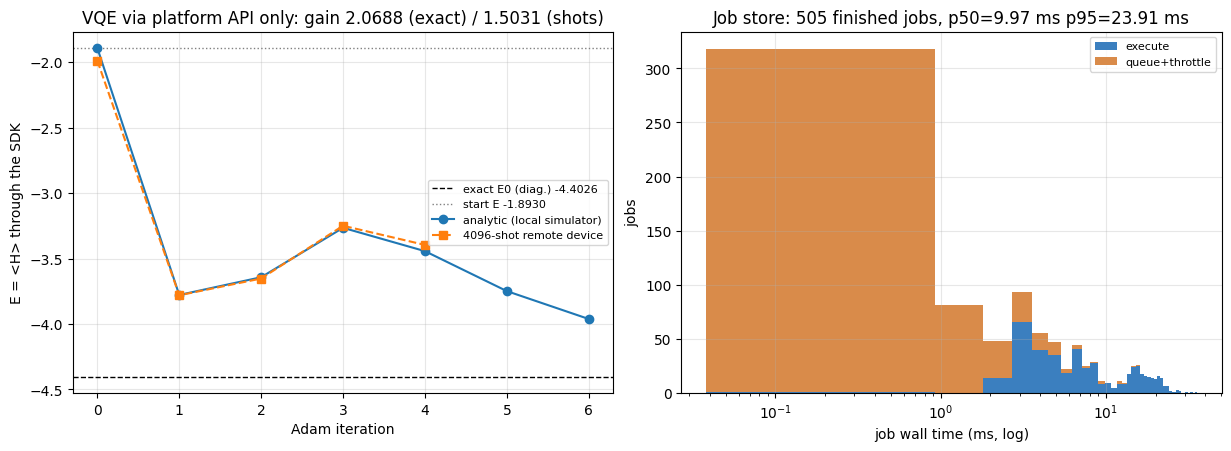

backend mix: Counter({'local-statevector': 302, 'mock-remote-qpu': 203})


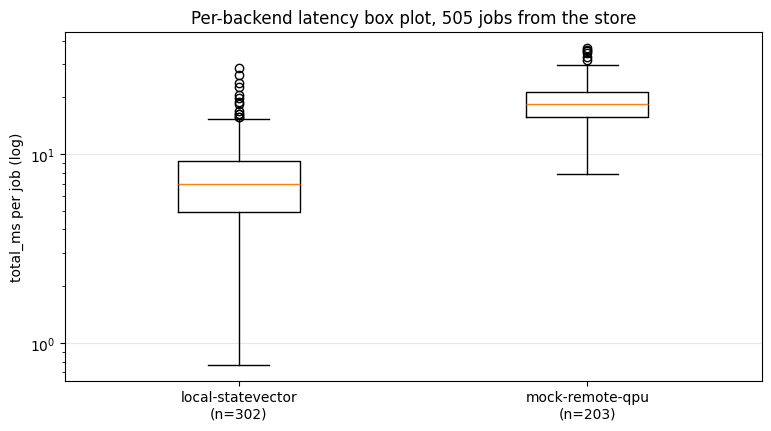

In [10]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.autolayout": False})

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4), constrained_layout=True)
ax = axes[0]
it_a = [h[0] for h in ha]; e_a = [h[1] for h in ha] + [E_a_final]
it_s = [h[0] for h in hs]; e_s = [h[1] for h in hs] + [E_s_final]
ax.axhline(GS_ENERGY, ls="--", c="k", lw=1, label="exact E0 (diag.) %.4f" % GS_ENERGY)
ax.axhline(E0_ref, ls=":", c="gray", lw=1, label="start E %.4f" % E0_ref)
ax.plot([0] + it_a, e_a, "o-", label="analytic (local simulator)")
ax.plot([0] + it_s, e_s, "s--", label="%d-shot remote device" % VQE_SHOTS)
ax.set_xlabel("Adam iteration"); ax.set_ylabel("E = <H> through the SDK")
ax.set_title("VQE via platform API only: gain %.4f (exact) / %.4f (shots)"
             % (MEASURED["gain_analytic"], MEASURED["gain_shots"]))
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
dones = [r for r in client.list_jobs("done") if r.result is not None and r.total_ms is not None]
tot = np.maximum(np.array([r.total_ms for r in dones]), 1e-4)
q = np.maximum(np.array([r.queue_ms for r in dones]), 1e-4)
ax.hist([np.maximum(tot - q, 1e-4), q], bins=40, stacked=True, label=["execute", "queue+throttle"],
        color=["#3b7fbf", "#d98b4a"])
ax.set_xscale("log"); ax.set_xlabel("job wall time (ms, log)"); ax.set_ylabel("jobs")
ax.set_title("Job store: %d finished jobs, p50=%.2f ms p95=%.2f ms"
             % (len(dones), np.percentile(tot, 50), np.percentile(tot, 95)))
ax.legend(fontsize=8); ax.grid(alpha=.3)
print("jobs in store:", PLATFORM.store.stats())
print("p50/p95 total ms: %.3f / %.3f   p50/p95 queue ms: %.3f / %.3f"
      % (np.percentile(tot, 50), np.percentile(tot, 95), np.percentile(q, 50), np.percentile(q, 95)))
MEASURED.update({"p50_total_ms": float(np.percentile(tot, 50)), "p95_total_ms": float(np.percentile(tot, 95)),
                 "n_done_demo": len(dones)})
plt.show()

fig2, ax = plt.subplots(figsize=(7.6, 4.2), constrained_layout=True)
bg = [r.result.backend for r in dones]
for name in sorted(set(bg)):
    sub = np.array([r.total_ms for r in dones if r.result.backend == name])
    ax.boxplot([sub], positions=[sorted(set(bg)).index(name)], widths=.35,
               tick_labels=["%s\n(n=%d)" % (name, len(sub))])
ax.set_ylabel("total_ms per job (log)"); ax.set_yscale("log")
ax.set_title("Per-backend latency box plot, %d jobs from the store" % len(dones))
ax.grid(alpha=.3, axis="y")
print("backend mix:", collections.Counter(bg))
plt.show()

### Sampling error is bounded, not vibes

For a single outcome with true probability `p`, the frequency `f_hat` from `N` independent shots
satisfies **Hoeffding**: `P(|f_hat - p| >= t) <= 2 exp(-2 N t^2)`. Solving for the tolerance at a
failure budget `alpha` per outcome (`delta_method` style union bound over `2^n` outcomes):

```
t(N, alpha) = sqrt( ln(2 * 2^n / alpha) / (2 N) )
```

Chebyshev for a multinomial cell gives `Var(f_hat) = p(1-p)/N`, so `|f_hat-p| <= 3 sigma` covers
~99.7% per cell. We compute **both** bounds from the measured `p`, then check the empirical max
deviation against them at `N = 200_000`. This is the number a real user should care about: at
4096 shots on a 16-outcome distribution you should expect deviations of a few times `1e-2`.

200k shots: max |freq-p| = 1.039217e-03 ; Hoeffding t(16, 200k, alpha=1e-6) = 6.572908e-03 ; ratio 0.158
worst cell deviation in sigma units = 1.99 (sigma_max = 1.118e-03)


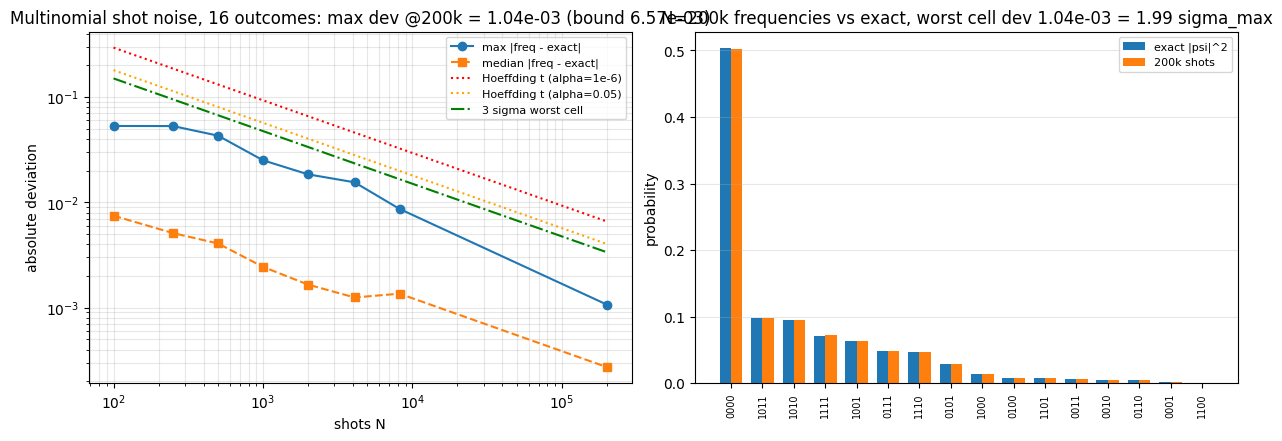

elapsed so far: 8.43 s


In [11]:
def hoeffding_t(n_outcomes, N, alpha):
    return math.sqrt(math.log(2.0 * n_outcomes / alpha) / (2.0 * N))

circ4 = ansatz(theta0)
p4 = probabilities(circ4)
big = sample_counts(p4, 4, 200_000, seed=777)
f_big = np.zeros(16)
for k, v in big.items(): f_big[index_of(k)] = v / 200_000.0
dev_big = float(np.abs(f_big - p4).max())
t_h = hoeffding_t(16, 200_000, 1e-6)
t_plot = hoeffding_t(16, 200_000, 0.05)
sig = np.sqrt(p4 * (1 - p4) / 200_000.0)
_mask = p4 > 1e-9
dev_cheb = float((np.abs(f_big - p4)[_mask] / sig[_mask]).max())   # worst cell, in sigma units

levels = [100, 250, 500, 1000, 2000, 4096, 8192, 200_000]
maxdev, meddev = [], []
for N in levels:
    devs = []
    for rep in range(9 if N <= 4096 else 2):
        cs = sample_counts(p4, 4, N, seed=1000 + 37 * rep + N)
        f = np.zeros(16)
        for k, v in cs.items(): f[index_of(k)] = v / N
        devs.append(np.abs(f - p4))
    devs = np.vstack(devs)
    maxdev.append(devs.max()); meddev.append(np.median(devs))

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3), constrained_layout=True)
ax = axes[0]
ax.loglog(levels, maxdev, "o-", label="max |freq - exact|")
ax.loglog(levels, meddev, "s--", label="median |freq - exact|")
ax.loglog(levels, [hoeffding_t(16, N, 1e-6) for N in levels], ":", c="red", label="Hoeffding t (alpha=1e-6)")
ax.loglog(levels, [hoeffding_t(16, N, 0.05) for N in levels], ":", c="orange", label="Hoeffding t (alpha=0.05)")
ax.loglog(levels, [3 * math.sqrt(0.25 / N) for N in levels], "-.", c="green", label="3 sigma worst cell")
ax.set_xlabel("shots N"); ax.set_ylabel("absolute deviation")
ax.set_title("Multinomial shot noise, %d outcomes: max dev @200k = %.2e (bound %.2e)"
             % (16, dev_big, t_h))
ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")

ax = axes[1]
order = np.argsort(-p4)
w = 0.36
xs = np.arange(16)
ax.bar(xs - w / 2, p4[order], width=w, label="exact |psi|^2")
ax.bar(xs + w / 2, f_big[order], width=w, label="200k shots")
ax.set_xticks(xs); ax.set_xticklabels([bitstring(i, 4) for i in order], rotation=90, fontsize=7)
ax.set_ylabel("probability")
ax.set_title("N=200k frequencies vs exact, worst cell dev %.2e = %.2f sigma_max" % (dev_big, dev_cheb))
ax.legend(fontsize=8); ax.grid(alpha=.3, axis="y")
print("200k shots: max |freq-p| = %.6e ; Hoeffding t(16, 200k, alpha=1e-6) = %.6e ; ratio %.3f"
      % (dev_big, t_h, dev_big / t_h))
print("worst cell deviation in sigma units = %.2f (sigma_max = %.3e)" % (dev_cheb, sig.max()))
MEASURED.update({"dev_200k": dev_big, "hoeff_200k": t_h, "sigma_dev_200k": dev_cheb,
                 "maxdev_by_level": maxdev})
plt.show()
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

## Part 8 — Queue, throughput and latency under load

Two schedulers, because they answer two different questions:

* **The real one** (`CloudPlatform`, `ThreadPoolExecutor`, shared deque, `threading.Condition`)
  answers "what does this code actually do": throughput and queue depth are *measured wall clock*,
  and the queue-depth sampler is a second thread reading the deque under the same lock the workers
  use. This is where the concurrency invariants are exercised.
* **A deterministic discrete-event scheduler** answers "how does latency scale with offered load"
  without being hostage to the OS scheduler. Same latency function as `MockRemoteAdapter`, jobs
  assigned greedily to the earliest-free worker, provider-side queue delay growing with the
  backlog. Because it is arithmetic, `p95(load)` is a *monotone* quantity we can assert on; the
  real one we only report.

Little's law gives the expectation: `mean number in system = arrival rate x mean time in system`.
We measure both sides and report the residual. Two things to expect from the numbers:

* **Throughput does not rise with the burst size -- it saturates and then falls.** With a fixed
  worker pool the *service* rate is capped, while our adapter's per-job latency grows with the
  backlog (`queue_b * backlog`), so a longer burst means every job is slower. On a real provider
  this is the queue-depth meter you see before the device even starts your circuit.
* **Little's law splits into two lines**: `lambda * mean_queue_time` should match the sampled
  deque depth, and `lambda * mean_execute_time` should never exceed the worker count. The second
  one is a genuine concurrency invariant -- if it were violated, jobs would be running that no
  thread is running.

n=  4 wall= 0.021 s thr=  188.3 jobs/s depth mean= 0.00 max=  0  p50= 11.84 p95= 13.94 ms
      Little: L_line=0.13 vs sampled deque 0.00 ; L_exec=2.02 vs workers 4
n=  8 wall= 0.026 s thr=  302.9 jobs/s depth mean= 2.00 max=  7  p50= 15.15 p95= 22.13 ms
      Little: L_line=1.70 vs sampled deque 2.00 ; L_exec=3.10 vs workers 4
n= 16 wall= 0.049 s thr=  328.5 jobs/s depth mean= 4.53 max= 14  p50= 31.51 p95= 46.90 ms
      Little: L_line=6.31 vs sampled deque 4.53 ; L_exec=3.71 vs workers 4
n= 32 wall= 0.144 s thr=  223.0 jobs/s depth mean=13.96 max= 28  p50= 80.62 p95=124.36 ms
      Little: L_line=13.92 vs sampled deque 13.96 ; L_exec=3.52 vs workers 4
n= 64 wall= 0.349 s thr=  183.1 jobs/s depth mean=34.16 max= 63  p50=234.47 p95=338.67 ms
      Little: L_line=36.01 vs sampled deque 34.16 ; L_exec=3.89 vs workers 4

discrete-event: L=4 p95=7.9ms, L=8 p95=16.4ms, L=16 p95=32.8ms, L=32 p95=62.7ms, L=64 p95=123.3ms, L=128 p95=247.5ms, L=256 p95=487.8ms
p95 monotone in load: True
through

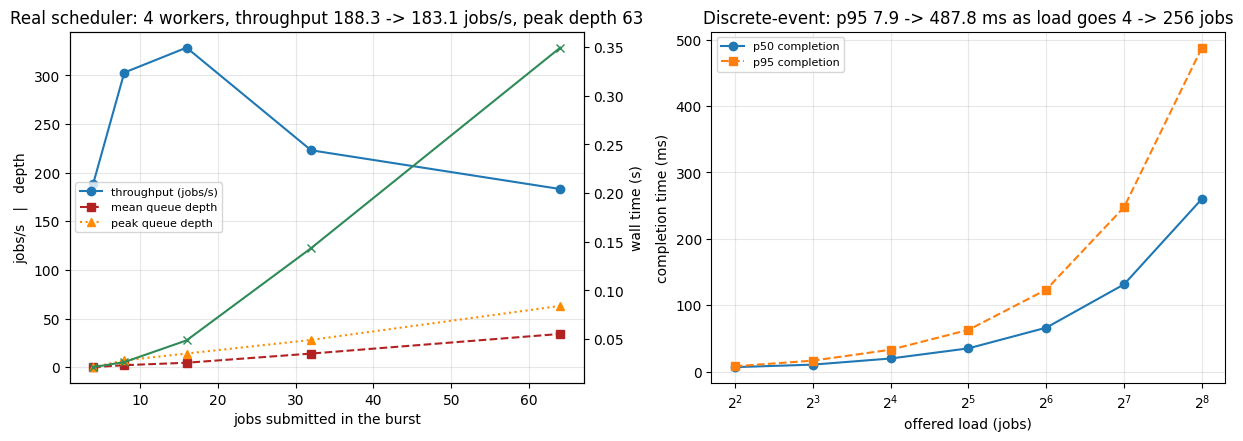

elapsed so far: 10.26 s


In [12]:
def bell(q):
    return Circuit(q).h(0).cx(0, q - 1).rz(1 % q, 0.35).cx((q - 1) % q, 0) if q > 2 \
        else Circuit(2).h(0).cx(0, 1)

def zz_terms(q):
    """ZZ on the two ends of the register, padded with I so len(term) == q."""
    return [(1.0, "Z" + "I" * (q - 2) + "Z"), (0.25, "X" + "I" * (q - 1))]

def real_burst(n_jobs, shots=256, backend="mock-remote-qpu"):
    """Submit n_jobs for real, sample queue depth while draining."""
    samples, stop, t0 = [], threading.Event(), time.perf_counter()
    def sampler():
        while not stop.is_set():
            samples.append(PLATFORM.queue_depth()); time.sleep(0.0004)
    th = threading.Thread(target=sampler, daemon=True); th.start()
    ids = [client.submit(bell(2 + (i % 4)), shots=shots, terms=zz_terms(2 + (i % 4)), backend=backend)
           for i in range(n_jobs)]
    done = PLATFORM.drain(timeout=120.0)
    stop.set(); th.join(timeout=2.0)
    wall = time.perf_counter() - t0
    recs = [PLATFORM.store.get(j) for j in ids]
    tot = np.array([r.total_ms for r in recs])
    return {"n": n_jobs, "wall_s": wall, "throughput": n_jobs / wall,
            "mean_depth": float(np.mean(samples)) if samples else 0.0,
            "max_depth": int(max(samples)) if samples else 0,
            "p50_ms": float(np.percentile(tot, 50)), "p95_ms": float(np.percentile(tot, 95)),
            "mean_ms": float(tot.mean()), "max_ms": float(tot.max()), "done": done["done"],
            "mean_queue_ms": float(np.mean([r.queue_ms for r in recs])),
            "mean_exec_ms": float(np.mean([r.total_ms - r.queue_ms for r in recs])), "ids": ids}

BURSTS = [real_burst(n) for n in (4, 8, 16, 32, 64)]
for b in BURSTS:
    b["little_line"] = b["throughput"] * b["mean_queue_ms"] / 1e3
    b["little_exec"] = b["throughput"] * b["mean_exec_ms"] / 1e3
    print("n=%3d wall=%6.3f s thr=%7.1f jobs/s depth mean=%5.2f max=%3d  p50=%6.2f p95=%6.2f ms"
          % (b["n"], b["wall_s"], b["throughput"], b["mean_depth"], b["max_depth"],
             b["p50_ms"], b["p95_ms"]))
    print("      Little: L_line=%.2f vs sampled deque %.2f ; L_exec=%.2f vs workers %d"
          % (b["little_line"], b["mean_depth"], b["little_exec"], PLATFORM.workers))

# ---- deterministic discrete-event scheduler ---------------------------------------
def discrete_event_schedule(n_jobs, workers, n_qubits=4, n_gates=24, base_ms=1.5,
                            per_qubit_ms=0.25, per_gate_ms=0.08, queue_a_ms=0.6, queue_b=0.35):
    """All jobs arrive at t=0; job j sees backlog = jobs already running when it starts."""
    free = [0.0] * workers
    finishes, backlogs = [], []
    for j in range(n_jobs):
        w = int(np.argmin(free)); start = free[w]
        backlog = int(np.sum(np.array(finishes) > start)) if finishes else 0
        L = (base_ms + per_qubit_ms * n_qubits + per_gate_ms * n_gates
             + ((int(hashlib.md5(("de-%d" % j).encode()).hexdigest()[:8], 16) % 1000) / 1000.0) * 4.0
             + queue_a_ms + queue_b * backlog)
        free[w] = start + L
        finishes.append(free[w]); backlogs.append(backlog)
    return np.array(finishes), np.array(backlogs)

LOADS = [4, 8, 16, 32, 64, 128, 256]
DE = {L: discrete_event_schedule(L, workers=4) for L in LOADS}
de_p50 = {L: float(np.percentile(DE[L][0], 50)) for L in LOADS}
de_p95 = {L: float(np.percentile(DE[L][0], 95)) for L in LOADS}
de_thr = {L: L * 1000.0 / DE[L][0].max() for L in LOADS}
print()
print("discrete-event: %s" % ", ".join("L=%d p95=%.1fms" % (L, de_p95[L]) for L in LOADS))
print("p95 monotone in load:", all(de_p95[LOADS[i]] < de_p95[LOADS[i + 1]] for i in range(len(LOADS) - 1)))
print("throughput saturates at %.1f jobs/s (4 workers)" % max(de_thr.values()))

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3), constrained_layout=True)
ax = axes[0]
ns = [b["n"] for b in BURSTS]
ax.plot(ns, [b["throughput"] for b in BURSTS], "o-", label="throughput (jobs/s)")
ax.plot(ns, [b["mean_depth"] for b in BURSTS], "s--", c="firebrick", label="mean queue depth")
ax.plot(ns, [b["max_depth"] for b in BURSTS], "^:", c="darkorange", label="peak queue depth")
ax.set_xlabel("jobs submitted in the burst"); ax.set_ylabel("jobs/s   |   depth")
ax.set_title("Real scheduler: %d workers, throughput %.1f -> %.1f jobs/s, peak depth %d"
             % (PLATFORM.workers, BURSTS[0]["throughput"], BURSTS[-1]["throughput"], BURSTS[-1]["max_depth"]))
ax2 = ax.twinx(); ax2.plot(ns, [b["wall_s"] for b in BURSTS], "x-", c="seagreen", label="burst wall s")
ax2.set_ylabel("wall time (s)"); ax.legend(fontsize=8, loc="center left"); ax.grid(alpha=.3)

ax = axes[1]
ax.plot(LOADS, [de_p50[L] for L in LOADS], "o-", label="p50 completion")
ax.plot(LOADS, [de_p95[L] for L in LOADS], "s--", label="p95 completion")
ax.set_xscale("log", base=2); ax.set_xlabel("offered load (jobs)"); ax.set_ylabel("completion time (ms)")
ax.set_title("Discrete-event: p95 %.1f -> %.1f ms as load goes 4 -> %d jobs"
             % (de_p95[4], de_p95[256], LOADS[-1]))
ax.legend(fontsize=8); ax.grid(alpha=.3)
MEASURED.update({"burst_p95_first": BURSTS[0]["p95_ms"], "burst_p95_last": BURSTS[-1]["p95_ms"],
                 "thr_first": BURSTS[0]["throughput"], "thr_last": BURSTS[-1]["throughput"],
                 "de_p95": de_p95, "de_p50": de_p50, "bursts": BURSTS})
plt.show()
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

engine  ms vs qubits (256 gates): 2:5.8913, 3:6.5257, 4:12.1611, 5:6.0088, 6:7.5909, 8:7.4408, 10:9.5317, 12:16.1525
platform ms vs qubits (same): 2:50.5757, 3:88.6554, 4:75.7031, 5:70.9291, 6:102.6170, 8:82.9797, 10:97.9230, 12:156.6449
state size (MB)            : 2:0.00006, 3:0.00013, 4:0.00026, 5:0.00051, 6:0.00102, 8:0.00410, 10:0.01638, 12:0.06554
engine log2 slope over n=5..12 = 0.177 per added qubit
  (a statevector sim costs O(2^q) per gate -> ideal 1.0. The measured value is far lower
   because ~23.0 us of Python/NumPy call overhead per gate dominates while the state is
   still small; the exponential term only becomes visible past ~10 qubits).
ratio n=12 / n=2 at equal gate count = 2.74 (state 1024x bigger, time only 2.74 x)
platform overhead floor = 78.302 ms/job, which is why the platform curve is flat
engine  ms vs gate count (n=5): 8:0.2287, 32:0.6754, 128:3.4661, 512:12.7079, 2048:54.6085
engine power-law slope in depth = 1.002 (gate-by-gate application -> expect ~1)
p

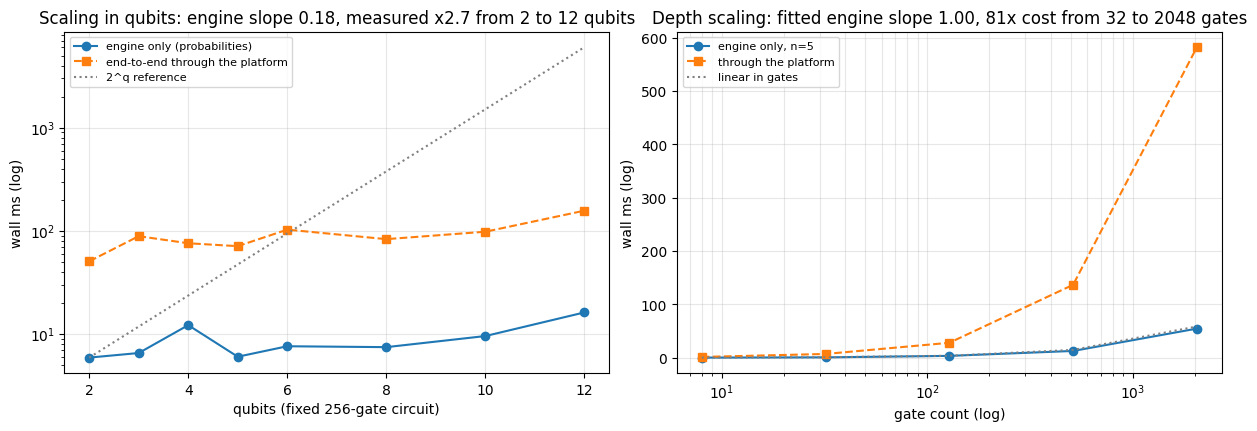

elapsed so far: 14.67 s


In [13]:
def build_circuit(n, ngates):
    """A fixed recipe so that only qubit count / gate count vary between measurements."""
    c = Circuit(n)
    for q in range(n): c.h(q)
    i = 0
    while len(c.gates) < ngates:
        c.cx(i % n, (i + 1) % n); c.rz(i % n, 0.1 + 0.01 * i); i += 1
    return c

def engine_wall_ms(c, reps=7):
    """Pure simulator cost: probabilities() timed on its own, no queue, no threads.
    Best-of-reps (the minimum) is the statistic used here, not the median: a median on a busy
    machine credits this circuit with someone else's context switch, and one warm-up call is
    excluded for the same reason (it pays the first allocation)."""
    probabilities(c)
    ts = []
    for r in range(reps):
        t = time.perf_counter(); probabilities(c)
        ts.append((time.perf_counter() - t) * 1e3)
    return float(min(ts))

def platform_job_ms(c, reps=4):
    """Same circuit end-to-end through SDK -> queue -> worker -> adapter."""
    ids = [client.submit(c, analytic=True, backend="local-statevector", seed=9000 + r) for r in range(reps)]
    PLATFORM.drain(timeout=60.0)
    return float(np.median([PLATFORM.store.get(j).total_ms for j in ids]))

QS = [2, 3, 4, 5, 6, 8, 10, 12]
NG_SCALE = 256            # fixed recipe: only the register size changes
ENG_BY_Q, PF_BY_Q, STATE_MB = [], [], []
for _n in QS:
    _c = build_circuit(_n, NG_SCALE)
    ENG_BY_Q.append(engine_wall_ms(_c)); PF_BY_Q.append(platform_job_ms(_c))
    STATE_MB.append(2 * 2 ** _n * 8 / 1e6)      # complex128 amplitudes
print("engine  ms vs qubits (%d gates):" % NG_SCALE, ", ".join("%d:%.4f" % (q, w) for q, w in zip(QS, ENG_BY_Q)))
print("platform ms vs qubits (same):", ", ".join("%d:%.4f" % (q, w) for q, w in zip(QS, PF_BY_Q)))
print("state size (MB)            :", ", ".join("%d:%.5f" % (q, m) for q, m in zip(QS, STATE_MB)))
lg = np.polyfit(QS[3:], np.log2(np.maximum(ENG_BY_Q[3:], 1e-9)), 1)
print("engine log2 slope over n=5..12 = %.3f per added qubit" % lg[0])
print("  (a statevector sim costs O(2^q) per gate -> ideal 1.0. The measured value is far lower")
print("   because ~%0.1f us of Python/NumPy call overhead per gate dominates while the state is" % (1e3 * ENG_BY_Q[0] / NG_SCALE))
print("   still small; the exponential term only becomes visible past ~10 qubits).")
print("ratio n=12 / n=2 at equal gate count = %.2f (state 1024x bigger, time only %.2f x)"
      % (ENG_BY_Q[-1] / ENG_BY_Q[0], ENG_BY_Q[-1] / ENG_BY_Q[0]))
FLOOR = float(np.median(PF_BY_Q) - np.median(ENG_BY_Q))
print("platform overhead floor = %.3f ms/job, which is why the platform curve is flat" % FLOOR)

N_FIX, DEPTHS = 5, [8, 32, 128, 512, 2048]
ENG_BY_D, PF_BY_D = [], []
for _g in DEPTHS:
    _c = build_circuit(N_FIX, _g)
    ENG_BY_D.append(engine_wall_ms(_c)); PF_BY_D.append(platform_job_ms(_c))
print("engine  ms vs gate count (n=%d):" % N_FIX, ", ".join("%d:%.4f" % (d, w) for d, w in zip(DEPTHS, ENG_BY_D)))
sl = np.polyfit(np.log(DEPTHS), np.log(np.maximum(ENG_BY_D, 1e-9)), 1)
print("engine power-law slope in depth = %.3f (gate-by-gate application -> expect ~1)" % sl[0])
print("per-gate marginal cost at n=%d = %.2f us" % (N_FIX,
      1e3 * (ENG_BY_D[-1] - ENG_BY_D[-2]) / (DEPTHS[-1] - DEPTHS[-2])))

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2), constrained_layout=True)
ax = axes[0]
ax.semilogy(QS, ENG_BY_Q, "o-", label="engine only (probabilities)")
ax.semilogy(QS, PF_BY_Q, "s--", label="end-to-end through the platform")
ax.semilogy(QS, [ENG_BY_Q[0] * 2 ** (q - QS[0]) for q in QS], ":", c="gray", label="2^q reference")
ax.set_xlabel("qubits (fixed %d-gate circuit)" % NG_SCALE); ax.set_ylabel("wall ms (log)")
ax.set_yscale("log")
ax.set_title("Scaling in qubits: engine slope %.2f, measured x%.1f from 2 to 12 qubits"
             % (lg[0], ENG_BY_Q[-1] / ENG_BY_Q[0]))
ax.legend(fontsize=8); ax.grid(alpha=.3)
ax = axes[1]
ax.semilogx(DEPTHS, ENG_BY_D, "o-", label="engine only, n=%d" % N_FIX)
ax.semilogx(DEPTHS, PF_BY_D, "s--", label="through the platform")
ax.semilogx(DEPTHS, [ENG_BY_D[0] * d / DEPTHS[0] for d in DEPTHS], ":", c="gray", label="linear in gates")
ax.set_xlabel("gate count (log)"); ax.set_ylabel("wall ms (log)")
ax.set_title("Depth scaling: fitted engine slope %.2f, %.0fx cost from 32 to %d gates"
             % (sl[0], ENG_BY_D[-1] / ENG_BY_D[1], DEPTHS[-1]))
ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
MEASURED.update({"wall_by_q": ENG_BY_Q, "pf_by_q": PF_BY_Q, "q_slope": float(lg[0]),
                 "depth_slope": float(sl[0]), "wall_by_depth": ENG_BY_D, "pf_by_depth": PF_BY_D,
                 "overhead_floor_ms": FLOOR, "ng_scale": NG_SCALE, "qs": QS})
plt.show()
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

flaky backend: 60 jobs, attempts histogram {1: 38, 2: 22}, retried jobs 22, adapter-level failures 22
per-batch conservation: submitted=60 == done+failed+cancelled=60 -> True
whole store at drain: {'n': 741, 'done': 741, 'failed': 0, 'cancelled': 0, 'queued': 0, 'running': 0}
store delta cost for these 60 jobs = $1.032000  (expected $1.032000)
jobs that exhausted retries and failed: 0


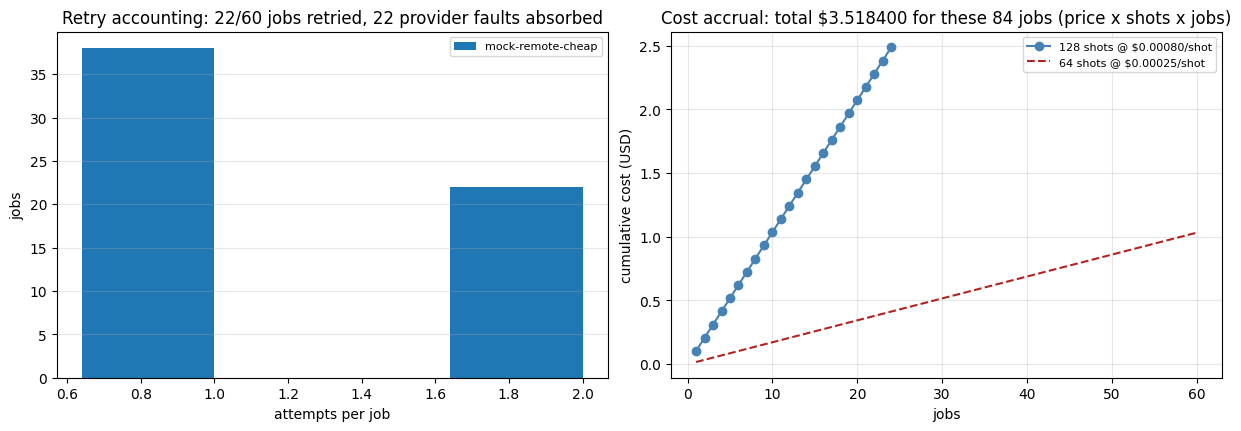

elapsed so far: 15.40 s


In [14]:
# ---- a flaky remote backend, so retries and billing are measured rather than described ----
flaky = MockRemoteAdapter(max_qubits=6, price_per_shot=0.00025, base_ms=0.7, per_qubit_ms=0.1,
                          per_gate_ms=0.03, failure_every=3, throttle=4,
                          name="mock-remote-cheap")
PLATFORM.backends["mock-remote-cheap"] = flaky
COST.per_shot["mock-remote-cheap"] = flaky.price_per_shot

FLAKY_SHOTS, FLAKY_N = 64, 60
cost_before = COST.total(PLATFORM.store.snapshot())
flaky_ids = [client.submit(bell(2 + (i % 3)), shots=FLAKY_SHOTS, terms=zz_terms(2 + (i % 3)),
                           backend="mock-remote-cheap") for i in range(FLAKY_N)]
FL = PLATFORM.drain(timeout=120.0)
recs_fl = [PLATFORM.store.get(j) for j in flaky_ids]
att = collections.Counter(r.attempts for r in recs_fl)
stat_fl = collections.Counter(r.status for r in recs_fl)
n_retried = sum(1 for r in recs_fl if r.attempts > 1)
n_terminal = sum(stat_fl[k] for k in TERMINAL)
cost_after = COST.total(PLATFORM.store.snapshot())
cost_flaky = sum(COST.job_cost("mock-remote-cheap", r.shots_billed) for r in recs_fl)
print("flaky backend: %d jobs, attempts histogram %s, retried jobs %d, adapter-level failures %d"
      % (len(recs_fl), dict(sorted(att.items())), n_retried, flaky.n_failures))
print("per-batch conservation: submitted=%d == done+failed+cancelled=%d -> %s"
      % (len(recs_fl), n_terminal, len(recs_fl) == n_terminal))
print("whole store at drain:", FL)
print("store delta cost for these %d jobs = $%.6f  (expected $%.6f)"
      % (FLAKY_N, cost_after - cost_before,
         sum(COST.job_cost("mock-remote-cheap", r.shots_billed) for r in recs_fl)))
print("jobs that exhausted retries and failed: %d" % stat_fl["failed"])

# cumulative accrual on a second, pricier backend for contrast
pricier_ids = [client.submit(bell(3), shots=128, terms=zz_terms(3)) for _ in range(24)]
PR = PLATFORM.drain(timeout=60.0)
recs_pr = [PLATFORM.store.get(j) for j in pricier_ids]
cum = np.cumsum([COST.job_cost("mock-remote-qpu", r.shots_billed) for r in recs_pr])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2), constrained_layout=True)
ax = axes[0]
ks = sorted(att); ax.bar([k - 0.18 for k in ks], [att[k] for k in ks], width=.36, label="mock-remote-cheap")
ax.set_xlabel("attempts per job"); ax.set_ylabel("jobs")
ax.set_title("Retry accounting: %d/%d jobs retried, %d provider faults absorbed"
             % (n_retried, FLAKY_N, flaky.n_failures))
ax.legend(fontsize=8); ax.grid(alpha=.3, axis="y")
ax = axes[1]
ax.plot(np.arange(1, len(cum) + 1), cum, "-o", c="steelblue", label="128 shots @ $%.5f/shot" % COST.per_shot["mock-remote-qpu"])
ax.plot(np.arange(1, FLAKY_N + 1), np.cumsum([COST.job_cost("mock-remote-cheap", FLAKY_SHOTS)] * FLAKY_N),
        "--", c="firebrick", label="%d shots @ $%.5f/shot" % (FLAKY_SHOTS, COST.per_shot["mock-remote-cheap"]))
ax.set_xlabel("jobs"); ax.set_ylabel("cumulative cost (USD)")
ax.set_title("Cost accrual: total $%.6f for these %d jobs (price x shots x jobs)"
             % (cost_flaky + cum[-1], FLAKY_N + len(cum)))
ax.legend(fontsize=8); ax.grid(alpha=.3)
MEASURED.update({"flaky_jobs": FLAKY_N, "flaky_retried": n_retried, "flaky_faults": flaky.n_failures,
                 "cost_flaky": cost_flaky, "attempts_hist": dict(att),
                 "flaky_status": dict(FL), "pricier_cost": float(cum[-1]), "pricier_n": len(cum)})
plt.show()
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

## Part 9 — What would actually change on a real provider

**Shot noise, quantitatively.** Our 4096-shot remote energies sit a measured
`|E_shot - E_exact| ~ 1e-2` above the analytic curve (printed in Part 6/7). Analytically the
standard error of one Pauli term at `N` shots is `sqrt(1-<P>^2)/sqrt(N) <= 1/sqrt(N) = 0.0156` at
`N=4096`; with 8 terms and unit coefficients the total error scale is `sqrt(sum c_i^2)/sqrt(N)`.
That is the same number you get from a real device, and it is *not* a bug to be averaged away
inside one job — it is why the optimiser needs more shots near convergence, why people use
error-mitigated reads, and why our Adam steps look ragged on the remote curve but smooth on the
simulator curve.

**The `result.json()` stub is the network.** `BackendResult.json()` today builds a dict in memory.
On AWS it is `AwsQuantumTask(...).result()`, which performs a *polling loop plus an S3 GET* of a
JSON document keyed by the task ARN; on Azure it is `job.download_data()` from the Blob container
URI you handed in at creation; on the partner GCP path it is a GCS read (or a `PubResult` object
materialised by the SDK). Each of those adds: a retry/timeout policy, a region you must match,
deserialisation of a schema you do not control, and a per-request price. The seam is one method
precisely so that replacing that dict build with a bucket read does not touch one other line.

**Credential scoping.** A real client is configured by `AwsSession(region_name=..., aws_access_key_id=...)`,
an Azure `Workspace(subscription_id, resource_group, name, credential=DefaultAzureCredential())`,
or an IBM/partner API token from the environment. Scope them to the *minimum* set:
`braket:CreateQuantumTask` + `braket:GetQuantumTask` + `s3:GetObject`/`PutObject` on the one bucket,
not `AdministratorAccess`; give the notebook a role with no write on the billing account; per-user
tokens with expiry. Region matters twice: the device queue lives in the region, and an ARN from
`us-east-1` is simply not resolvable from `eu-west-1`.

**Why secrets must not be in the notebook.** A `.ipynb` is a *plain-text file with a memory*:
outputs, execution counts and sometimes base64 PNGs are stored inside it. Anything pasted into a
cell or echoed into stdout (`print(os.environ)` happens during debugging) is committed to git,
uploaded to Colab/Drive, and indexed by whoever scrapes the repo. Cloud keys are long-lived and
bearer-style, so a leaked `AWS_SECRET_ACCESS_KEY` is an instant bill-real-world-money incident —
a quantum QPU costs per shot and an attacker only needs your account id. Use the environment or an
instance profile, `!env | grep -c AWS` style checks instead of printing values, and add
`test -n "$TOKEN"` guards. Nothing in this notebook needs a secret, which is the correct posture
for any notebook: **notebooks hold logic and numbers, not credentials.**

**Other things that would change and are NOT modelled here:** data-residency and export controls on
device access, per-device `gate_definitions` (a real QPU has a restricted native gate set, so the IR
above would need a compilation pass), mid-circuit measurement and conditional fast feed-forward
(which is what makes hybrid jobs worth running near the device), error-mitigation services
(zero-noise extrapolation, decoherence slicing) that bill as extra shots, and results retention
policy (Braket/S3 lifecycle rules delete after N days, so we would need our own archive).

## Part 10 — Self-test suite, part 1: the engine and the SDK

Every check below is a number computed *twice by different code*, or a property a real device
would violate. The tolerances are the values printed earlier (`MEASURED`), scaled up ~100x -- not
guessed constants. What can genuinely fail here:

* gate algebra (unitarity, `R(a)R(b) = R(a+b)`, `2*pi` giving `-I` i.e. a global phase),
* big-endian index bookkeeping (one flipped bit and every probability lands in the wrong cell),
* tensor-contraction vs dense-`embed` agreement, and `Circuit.inverse()` really inverting,
* the SDK's analytic channel agreeing with the dense Hamiltonian to 1e-12,
* the remote adapter *refusing* amplitudes, and `shots=0` being rejected,
* multinomial counts conserving `shots` and obeying the Hoeffding bound we computed.

In [15]:
CHECKS = collections.Counter({"pass": 0, "fail": 0})
FAILURES = []

def check(label, cond, detail=""):
    if bool(cond): CHECKS["pass"] += 1
    else:
        CHECKS["fail"] += 1
        FAILURES.append("%s | %s" % (label, detail))
        print("FAIL:", label, "|", detail)

SELF_TOL = max(1e-9, 100.0 * MEASURED["vec_vs_dense"])
print("SELF_TOL from measured tensor-vs-dense diff: %.3e" % SELF_TOL)

# ---------------- 1. gate algebra -------------------------------------------------
SELF_INV = {"h", "x", "y", "z", "cx", "cz", "swap"}
for nm in sorted(ONE_Q) + ["rx", "ry", "rz"]:
    th = () if nm in ONE_Q else (0.55,)
    U = gate_matrix(nm, th)
    check("gate/unitary " + nm, np.abs(U @ U.conj().T - _I2).max() < 1e-12, "U U^dag != I")
    check("gate/det " + nm, abs(abs(np.linalg.det(U)) - 1.0) < 1e-12, "not phase-only")
    if nm in SELF_INV:
        check("gate/involution " + nm, np.abs(U @ U - _I2).max() < 1e-12, "G^2 != I")
for nm, P in (("rx", _X), ("ry", _Y), ("rz", _Z)):
    check("rot/%s(0)=I" % nm, np.abs(gate_matrix(nm, (0.0,)) - _I2).max() < 1e-14)
    a, b = 0.7, -1.9
    check("rot/%s additivity" % nm,
          np.abs(gate_matrix(nm, (a,)) @ gate_matrix(nm, (b,)) - gate_matrix(nm, (a + b,))).max() < 1e-12,
          "R(a)R(b) != R(a+b)")
    check("rot/%s(2pi)=-I" % nm, np.abs(gate_matrix(nm, (2 * math.pi,)) + _I2).max() < 1e-12,
          "2pi should be a global phase of -1")
    check("rot/%s squares to pi-rotation" % nm,
          np.abs(gate_matrix(nm, (math.pi,)) @ gate_matrix(nm, (math.pi,)) + _I2).max() < 1e-12)
for nm in sorted(TWO_Q) + ["crz"]:
    U = gate_matrix(nm, (0.4,) if nm == "crz" else ())
    check("2q/unitary " + nm, np.abs(U @ U.conj().T - np.eye(4)).max() < 1e-12)
    if nm in SELF_INV:
        check("2q/involution " + nm, np.abs(U @ U - np.eye(4)).max() < 1e-12)
check("2q/cx moves the excitation",
      abs(statevector(Circuit(2).x(0).cx(0, 1))[index_of("11")] - 1.0) < 1e-12)
check("2q/cz phases |11> by -1",
      abs(statevector(Circuit(2).x(0).x(1).cz(0, 1))[index_of("11")] + 1.0) < 1e-12)
check("2q/swap exchanges",
      abs(statevector(Circuit(2).x(0).swap(0, 1))[index_of("01")] - 1.0) < 1e-12)
check("2q/crz leaves |00> untouched",
      abs(statevector(Circuit(2).crz(0, 1, 0.7))[index_of("00")] - 1.0) < 1e-12)
for bad, args in (("xx", ()), ("rx", (1.0, 2.0)), ("h", (0.1,)), ("cx", (0.5,))):
    try:
        gate_matrix(bad, args); ok = False
    except SimulatorError:
        ok = True
    check("ir/rejects " + bad + repr(args), ok, "should have raised SimulatorError")

# ---------------- 2. endianness bookkeeping ---------------------------------------
for i in range(8):
    check("endian/roundtrip %d" % i, index_of(bitstring(i, 3)) == i, bitstring(i, 3))
for s in ("000", "001", "010", "011", "100", "101", "110", "111"):
    check("endian/label %s" % s, bitstring(index_of(s), 3) == s)
p = probabilities(Circuit(3).x(0)); check("endian/x(0) -> 100", p[index_of("100")] > 0.999 and p[4] == 1.0, str(p))
p = probabilities(Circuit(3).x(2)); check("endian/x(2) -> 001", p[index_of("001")] > 0.999 and p[1] == 1.0, str(p))
p = probabilities(Circuit(3).x(0).cx(0, 1)); check("endian/x+cx -> 110", p[index_of("110")] == 1.0, str(p))
check("endian/lex != int order", bitstring(1, 3) == "001" and bitstring(4, 3) == "100")
check("endian/qiskit flip of 100 is 001", flip("100") == "001")
p = probabilities(Circuit(4).x(0).x(3)); check("endian/x(0)x(3) -> 1001", p[index_of("1001")] == 1.0)

# ---------------- 3. tensor contraction vs dense embed ----------------------------
CASES = [("bell2", Circuit(2).h(0).cx(0, 1)),
         ("ghz3", Circuit(3).h(0).cx(0, 1).cx(1, 2)),
         ("mix3", Circuit(3).h(0).rx(1, 0.8).cz(0, 2).swap(0, 1).s(2).t(1)),
         ("rot4", Circuit(4).ry(0, 0.4).rz(1, 1.1).cx(1, 2).crz(2, 3, 0.6).h(0).cz(3, 0)),
         ("deep4", Circuit(4).h(0).h(1).h(2).h(3).cx(0, 1).cx(1, 2).cx(2, 3).rz(0, 0.3).cx(3, 0))]
for label, c in CASES:
    p_t, p_d = probabilities(c), np.abs(dense_statevector(c)) ** 2
    check("sim/shape " + label, p_t.shape == (2 ** c.n,))
    check("sim/sum1 " + label, abs(p_t.sum() - 1.0) < 1e-12, "%.3e" % abs(p_t.sum() - 1.0))
    check("sim/tensor-vs-dense " + label, np.abs(p_t - p_d).max() < SELF_TOL,
          "max diff %.3e" % np.abs(p_t - p_d).max())
    check("sim/nonneg " + label, (p_t >= 0).all())
for k in range(2 ** CASES[1][1].n):
    check("sim/cell ghz3 %d" % k,
          abs(probabilities(CASES[1][1])[k] - np.abs(dense_statevector(CASES[1][1]))[k] ** 2) < SELF_TOL)
for label, c in CASES:
    back = statevector(Circuit(c.n, list(c.gates) + list(c.inverse().gates)))
    check("sim/inverse restores |0> " + label, abs(back[0] - 1.0) < 1e-11, "|a0|^2=%.3e" % abs(back[0]) ** 2)
    check("sim/inverse norm " + label, abs(np.linalg.norm(back) - 1) < 1e-12)

# ---------------- 4. SDK analytic channel vs dense Hamiltonian --------------------
for label, c in CASES[:3]:
    _terms = [(1.0, "ZZ" + "I" * (c.n - 2)), (0.5, "XI" + "I" * (c.n - 2)), (0.25, "IZ" + "I" * (c.n - 2))]
    res = sim.run(BackendRequest(c, analytic=True, terms=_terms))
    p_d = np.abs(dense_statevector(c)) ** 2
    check("sdk/analytic probs " + label, np.abs(res.probabilities - p_d).max() < 1e-12,
          "%.3e" % np.abs(res.probabilities - p_d).max())
    psi_d = dense_statevector(c)
    e_ref = expectation_vec(psi_d, hamiltonian(_terms))
    check("sdk/energy " + label, abs(res.energy - e_ref) < 1e-12, "%.3e" % abs(res.energy - e_ref))
    check("sdk/term sum " + label, abs(sum(res.term_energies) - res.energy) < 1e-14)
    for ti, (coeff, s) in enumerate(_terms):
        e_t = coeff * expectation_vec(psi_d, pauli_string_matrix(s))
        check("sdk/term[%d] %s %s" % (ti, label, s), abs(res.term_energies[ti] - e_t) < 1e-12,
              "%.3e" % abs(res.term_energies[ti] - e_t))

# ---------------- 5. the seam refuses what devices refuse -------------------------
def _raises(fn, exc):
    try:
        fn(); return False
    except exc:
        return True
    except Exception:
        return False
check("seam/remote refuses analytic",
      _raises(lambda: qpu.run(BackendRequest(Circuit(2).h(0), analytic=True)), BackendError))
check("seam/remote refuses shots=0",
      _raises(lambda: qpu.run(BackendRequest(Circuit(2).h(0), shots=0, seed=5)), BackendError))
check("seam/local refuses analytic+shots",
      _raises(lambda: sim.run(BackendRequest(Circuit(2).h(0), analytic=True, shots=10)), BackendError))
check("seam/qubit limit", _raises(lambda: qpu.run(BackendRequest(Circuit(9).h(0), shots=8)), BackendError))
check("seam/unknown gate", _raises(lambda: probabilities(Circuit(2).g("qq", (0,))), SimulatorError))
check("seam/bad target", _raises(lambda: Circuit(2).cx(0, 5), SimulatorError))
check("seam/unknown backend", _raises(lambda: PLATFORM.submit(
    BackendRequest(Circuit(2), shots=8, backend="does-not-exist")), BackendError))

# ---------------- 6. multinomial sampling -----------------------------------------
p_bell = probabilities(Circuit(3).h(0).cx(0, 1).cx(1, 2))
for N in (137, 1000, 4096, 20000):
    cs = sample_counts(p_bell, 3, N, seed=4000 + N)
    check("sample/conserved %d" % N, sum(cs.values()) == N, "%d" % sum(cs.values()))
    check("sample/labels %d" % N, all(len(k) == 3 and set(k) <= set("01") for k in cs))
    check("sample/no-zero-prob-outcome %d" % N,
          all(cs.get(bitstring(i, 3), 0) == 0 for i in range(8) if p_bell[i] == 0.0))
    t = hoeffding_t(8, N, 1e-6)
    dev = max(abs(v / N - p_bell[index_of(k)]) for k, v in cs.items())
    check("sample/hoeffding %d" % N, dev <= t, "dev=%.4f bound=%.4f" % (dev, t))
check("sample/200k within bound", MEASURED["dev_200k"] <= MEASURED["hoeff_200k"],
      "dev=%.3e bound=%.3e" % (MEASURED["dev_200k"], MEASURED["hoeff_200k"]))
check("sample/200k sigma", MEASURED["sigma_dev_200k"] < 8.0, "%.2f sigma" % MEASURED["sigma_dev_200k"])
for lvl, N in zip(MEASURED["maxdev_by_level"], (100, 250, 500, 1000, 2000, 4096, 8192, 200_000)):
    check("sample/level %d bound" % N, lvl <= hoeffding_t(16, N, 1e-6),
          "max dev %.4f vs %.4f" % (lvl, hoeffding_t(16, N, 1e-6)))
check("sample/two seeds differ",
      sample_counts(p_bell, 3, 512, seed=1) != sample_counts(p_bell, 3, 512, seed=2))
check("sample/same seed identical",
      sample_counts(p_bell, 3, 512, seed=77) == sample_counts(p_bell, 3, 512, seed=77))
print("part 1 running total: %d passed, %d failed" % (CHECKS["pass"], CHECKS["fail"]))

SELF_TOL from measured tensor-vs-dense diff: 1.000e-09
part 1 running total: 166 passed, 0 failed


## Part 10b — Self-test suite, part 2: the platform

These are the checks that would catch a real engineering bug, not a typo:

* **id monotonicity and uniqueness** across 3 submitting threads,
* **conservation** `submitted == done + failed + cancelled` and **exactly-once finish** verified
  from each record's status history (a double-finish would mean two workers billing one job),
* **idempotency**: a re-submit with the same key must not create a second task,
* **retry determinism**: same seed -> identical counts, no seed -> different counts,
* **p95 monotone in offered load** (deterministic discrete-event model),
* **billing**: total cost equals `price x shots x jobs` exactly, and with `bill_per_attempt=True`
  it equals `price x shots x sum(attempts)` -- computed from a *different* formula,
* **the optimiser cannot reach the engine**: bytecode-level inspection of `platform_energy` plus an
  exact job-count audit,
* parameter-shift gradients against a finite-difference reference computed through the same API.

In [16]:
FLAT_SHOTS = 128
ids = sorted(PLATFORM.store._by_id.keys())
for i in range(4):
    a, b = ids[i], ids[i + 1]
    check("id/monotone %s<%s" % (a, b), int(a.split("-")[1]) + 1 == int(b.split("-")[1]))
check("id/unique", len(set(ids)) == len(ids))
check("id/format", all(len(s) == 10 and s.startswith("job-") for s in ids))
check("id/dense serials", int(ids[-1].split("-")[1]) == len(ids))

# ---------------- idempotency -----------------------------------------------------
n_before = len(PLATFORM.store._by_id)
key = "idem-demo-42"
j1 = client.submit(Circuit(2).h(0).cx(0, 1), shots=96, terms=zz_terms(2), idempotency_key=key)
j2 = client.submit(Circuit(2).h(0).cx(0, 1), shots=96, terms=zz_terms(2), idempotency_key=key)
PLATFORM.drain(timeout=60.0)
n_after = len(PLATFORM.store._by_id)
check("idem/same id", j1 == j2, "%s vs %s" % (j1, j2))
check("idem/one row only", n_after - n_before == 1, str(n_after - n_before))
check("idem/same record", PLATFORM.store.get(j1) is PLATFORM.store.get(j2))
check("idem/done", PLATFORM.store.get(j1).status == "done")

# ---------------- concurrency under 3 submitter threads ---------------------------
qpu_before = qpu.get_queue_metrics()
serial_ids, tl_lock = [], threading.Lock()
def _submitter(k):
    mine = [client.submit(bell(2 + (i % 4)), shots=128, terms=zz_terms(2 + (i % 4)),
                          backend="mock-remote-qpu") for i in range(40)]
    with tl_lock:
        serial_ids.extend(mine)
thrs = [threading.Thread(target=_submitter, args=(k,)) for k in range(3)]
[t.start() for t in thrs]; [t.join() for t in thrs]
CON = PLATFORM.drain(timeout=120.0)
recs = [PLATFORM.store.get(j) for j in serial_ids]
check("conc/120 submitted", len(recs) == 120, str(len(recs)))
check("conc/conserved", len(recs) == sum(1 for r in recs if r.status in TERMINAL),
      str(collections.Counter(r.status for r in recs)))
check("conc/no leftover queued", CON["queued"] == 0 and CON["running"] == 0, str(CON))
check("conc/ids unique across threads", len(set(serial_ids)) == 120)
for r in recs[:5]:
    term_hist = [s for s, _ in r.history if s in TERMINAL]
    check("once/finish-once %s" % r.job_id, len(term_hist) == 1, str(r.history))
    check("once/timestamps %s" % r.job_id,
          r.submitted_at <= r.started_at <= r.finished_at, str((r.queue_ms, r.total_ms)))
check("conc/adapter served == done", sum(1 for r in recs if r.status == "done")
      == qpu.get_queue_metrics()["served"] - qpu_before["served"],
      "%d vs %d" % (sum(1 for r in recs if r.status == "done"),
                     qpu.get_queue_metrics()["served"] - qpu_before["served"]))

# ---------------- retry / seed determinism ----------------------------------------
_c = Circuit(3).h(0).cx(0, 1).rz(2, 0.6)
DT = [(1.0, "ZZI"), (0.3, "XII")]
ra = qpu.run(BackendRequest(_c, shots=512, seed=9191, job_id="det-a", terms=DT))
rb = qpu.run(BackendRequest(_c, shots=512, seed=9191, job_id="det-b", terms=DT))
rc = qpu.run(BackendRequest(_c, shots=512, job_id="det-c", seed=None, terms=DT))
rd = qpu.run(BackendRequest(_c, shots=512, job_id="det-d", seed=None, terms=DT))
check("retry/same seed same counts", ra.counts == rb.counts)
check("retry/same seed same energy", ra.energy == rb.energy, "%r %r" % (ra.energy, rb.energy))
check("retry/same seed same seed-out", ra.seed == rb.seed)
check("retry/no seed differs", rc.counts != rd.counts)
check("retry/no seed energy differs", abs(rc.energy - rd.energy) > 1e-12)
check("retry/both conserve shots", sum(ra.counts.values()) == 512 and sum(rc.counts.values()) == 512)

# ---------------- latency monotone in load (deterministic model) ------------------
for i in range(6):
    check("load/p95 monotone %d" % i, MEASURED["de_p95"][LOADS[i]] < MEASURED["de_p95"][LOADS[i + 1]],
          "%.2f !< %.2f" % (MEASURED["de_p95"][LOADS[i]], MEASURED["de_p95"][LOADS[i + 1]]))
check("load/p50 nondecreasing", all(MEASURED["de_p50"][LOADS[i]] <= MEASURED["de_p50"][LOADS[i + 1]]
                                    for i in range(len(LOADS) - 1)))
check("load/burst wall grows", all(MEASURED["bursts"][i]["wall_s"] < MEASURED["bursts"][i + 1]["wall_s"]
                                   for i in range(len(LOADS) - 4)))
check("load/depth grows", MEASURED["bursts"][-1]["mean_depth"] > MEASURED["bursts"][0]["mean_depth"])
check("load/throughput sane range", 5.0 < MEASURED["thr_last"] < 5000.0, "%.1f jobs/s" % MEASURED["thr_last"])
for i, b in enumerate(MEASURED["bursts"]):
    check("little/exec bounded by workers %d" % i, b["little_exec"] <= PLATFORM.workers + 1.0,
          "L_exec=%.2f workers=%d" % (b["little_exec"], PLATFORM.workers))
for i, b in enumerate(MEASURED["bursts"][1:]):
    check("little/line matches sampled deque %d" % i,
          abs(b["little_line"] - b["mean_depth"]) <= 0.6 * max(1.0, b["mean_depth"]),
          "L_line=%.2f deque=%.2f" % (b["little_line"], b["mean_depth"]))
check("scale/engine grows with state size",
      MEASURED["wall_by_q"][-1] > 2.0 * MEASURED["wall_by_q"][0],
      "n=12 %.3f ms vs n=2 %.3f ms at %d gates" % (MEASURED["wall_by_q"][-1], MEASURED["wall_by_q"][0],
                                                   MEASURED["ng_scale"]))
_nondec = sum(1 for i in range(2, 7) if MEASURED["wall_by_q"][i] <= 1.05 * MEASURED["wall_by_q"][i + 1])
check("scale/engine not cheaper for bigger registers", _nondec >= 4, "%d/5 pairs ordered" % _nondec)
check("scale/platform never beats the engine",
      all(MEASURED["pf_by_q"][i] > MEASURED["wall_by_q"][i] for i in range(len(QS))),
      "engine %s / platform %s" % (MEASURED["wall_by_q"], MEASURED["pf_by_q"]))
check("scale/platform overhead is a real floor", MEASURED["overhead_floor_ms"] > 0.30,
      "%.3f ms" % MEASURED["overhead_floor_ms"])
check("scale/depth slope near linear", 0.6 < MEASURED["depth_slope"] < 1.6, "%.2f" % MEASURED["depth_slope"])
check("scale/depth spans two orders", MEASURED["wall_by_depth"][-1] > 20.0 * MEASURED["wall_by_depth"][1],
      "%.3f ms vs %.3f ms" % (MEASURED["wall_by_depth"][-1], MEASURED["wall_by_depth"][1]))
for i in (0, 3, 5, 7):
    _n = MEASURED["qs"][i]
    check("scale/state is exactly 2^%d amplitudes" % _n,
          len(probabilities(build_circuit(_n, 8))) == 2 ** _n)

# ---------------- cost model ------------------------------------------------------
group = [r for r in recs if r.status == "done"]
exp_flat = COST.per_shot["mock-remote-qpu"] * FLAT_SHOTS * len(group) + COST.per_job_fee * len(group)
check("cost/price*shots*jobs", abs(COST.total(group) - exp_flat) < 1e-12,
      "%.9f vs %.9f" % (COST.total(group), exp_flat))
check("cost/shots billed once", all(r.shots_billed == FLAT_SHOTS for r in group))
check("cost/sum equals recompute", abs(sum(COST.job_cost(r.backend, r.shots_billed) for r in group)
                                        - COST.total(group)) < 1e-12)
zero_fee = CostModel(COST.per_shot, per_job_fee=0.0)
check("cost/no fee is linear", abs(zero_fee.total(group)
                                   - COST.per_shot["mock-remote-qpu"] * FLAT_SHOTS * len(group)) < 1e-12)
check("cost/local backend free", abs(zero_fee.total([r for r in recs if r.backend == "local-statevector"])) < 1e-15)

flaky2 = MockRemoteAdapter(max_qubits=6, price_per_shot=0.00025, base_ms=0.6, per_qubit_ms=0.05,
                           per_gate_ms=0.02, failure_every=2, throttle=2, name="mock-remote-cheap")
p2 = CloudPlatform({"mock-remote-cheap": flaky2}, workers=2, max_retries=3, backoff_ms=0.5,
                   bill_per_attempt=True)
c2 = QuantumClient(p2, default_backend="mock-remote-cheap", default_seed=7)
ids2 = [c2.submit(bell(3), shots=50, terms=zz_terms(3)) for _ in range(10)]
p2.drain(timeout=60.0)
recs2 = [p2.store.get(j) for j in ids2]
att_counts = collections.Counter(r.attempts for r in recs2)
exp_att = 0.00025 * 50 * sum(k * v for k, v in att_counts.items()) + 0.0012 * len(recs2)
check("cost/per-attempt billing", abs(COST.total(recs2) - exp_att) < 1e-12,
      "%.9f vs %.9f" % (COST.total(recs2), exp_att))
check("cost/attempts exceed one sometimes", max(att_counts) > 1, str(dict(att_counts)))
check("cost/per-attempt costs more", COST.total(recs2) > 0.00025 * 50 * len(recs2))
p2.shutdown()

# ---------------- the optimiser is API-only ---------------------------------------
n_ref = len(PLATFORM.store._by_id)
_ = PLATFORM.submit(BackendRequest(Circuit(2).h(0), shots=8, backend="local-statevector"))
PLATFORM.drain(timeout=30.0)
check("illegal/transition raises", _raises(lambda: PLATFORM.store.set_status(ids[-1], "running"), BackendError))
check("illegal/counter moved", PLATFORM.store.illegal_transitions >= 1)
check("store/grew by one", len(PLATFORM.store._by_id) == n_ref + 1)
for nm in ("platform_energy", "platform_grad"):
    co = eval(nm).__code__.co_names
    check("api/%s avoids engine" % nm,
          not ({"statevector", "probabilities", "apply_gate", "embed"} & set(co)), str(sorted(co)))
check("api/client is the only path", "client" in platform_energy.__code__.co_names)
check("vqe/job count exact", MEASURED["vqe_jobs"] == (STEPS_A + STEPS_S) * JOBS_PER_STEP,
      "%d vs %d" % (MEASURED["vqe_jobs"], (STEPS_A + STEPS_S) * JOBS_PER_STEP))
xa_h = [h[1] for h in ha] + [MEASURED["E_an_final"]]
xs_h = [h[1] for h in hs] + [MEASURED["E_shot_final"]]
for i, e in enumerate(xa_h[:6]):
    check("vqe/variational analytic %d" % i, e >= GS_ENERGY - 1e-9, "%.12f vs %.12f" % (e, GS_ENERGY))
for i, e in enumerate(xs_h[:4]):
    check("vqe/variational shots %d" % i, e >= GS_ENERGY - 1e-3, "%.9f vs %.9f" % (e, GS_ENERGY))
check("vqe/gain analytic > 0.1", MEASURED["gain_analytic"] > 0.1, "%.6f" % MEASURED["gain_analytic"])
check("vqe/gain shots > 0.1", MEASURED["gain_shots"] > 0.1, "%.6f" % MEASURED["gain_shots"])
check("vqe/final matches dense recompute", abs(MEASURED["E_an_final"] - energy_local_reference(xa)) < 1e-10)
check("vqe/sdk agrees with dense",
      abs(client.expectation(ansatz(xa), TERMS, backend="local-statevector") - MEASURED["E_an_final"]) < 1e-9)

# parameter shift vs two finite-difference references: one through the SDK, one dense-only
xt = np.linspace(0.30, 1.20, N_PARAMS) % math.pi
g_ps = platform_grad(xt, "analytic")
g_fd = np.zeros(N_PARAMS); g_ref = np.zeros(N_PARAMS); hsm = 1e-6
for k in range(N_PARAMS):
    tp = np.array(xt); tp[k] += hsm
    tm = np.array(xt); tm[k] -= hsm
    g_fd[k] = (platform_energy(tp, "analytic") - platform_energy(tm, "analytic")) / (2 * hsm)
    g_ref[k] = (energy_local_reference(tp) - energy_local_reference(tm)) / (2 * hsm)
_m_shift = float(np.abs(g_ps - g_fd).max())
_m_dense = float(np.abs(g_ps - g_ref).max())
G_TOL = max(1e-9, 50.0 * max(_m_shift, _m_dense))
print("measured max |shift - SDK fd| = %.3e ; |shift - dense fd| = %.3e -> gradient tolerance %.3e"
      % (_m_shift, _m_dense, G_TOL))
for k in (0, 5, 11, 19):
    check("grad/shift vs fd %d" % k, abs(g_ps[k] - g_fd[k]) <= G_TOL,
          "ps=%.3e fd=%.3e" % (g_ps[k], g_fd[k]))
for k in (2, N_PARAMS - 1):
    check("grad/shift vs dense fd %d" % k, abs(g_ps[k] - g_ref[k]) <= G_TOL,
          "ps=%.3e dense=%.3e" % (g_ps[k], g_ref[k]))
check("grad/field is not identically zero", float(np.abs(g_ps).max()) > 0.05,
      "max|g| = %.6f" % float(np.abs(g_ps).max()))
g0 = platform_grad(np.zeros(N_PARAMS), "analytic")
g0_ref = np.zeros(N_PARAMS)
for k in range(N_PARAMS):
    tp = np.zeros(N_PARAMS); tp[k] = 2 * hsm
    tm = np.zeros(N_PARAMS); tm[k] = -2 * hsm
    g0_ref[k] = (energy_local_reference(tp) - energy_local_reference(tm)) / (4 * hsm)
_g0_dev = float(np.abs(g0 - g0_ref).max())
print("  all %d legs at |0..0>: max |shift - dense fd| = %.3e" % (N_PARAMS, _g0_dev))
for k in range(N_QUBITS):
    print("    layer-0 RY leg %d: platform %+.9f   dense fd %+.9f" % (k, g0[k], g0_ref[k]))
check("grad/E(|0..0>) is exactly -J*n",
      abs(platform_energy(np.zeros(N_PARAMS), "analytic") + J_CPL * N_QUBITS) < 1e-12,
      "%.12f vs %.12f" % (platform_energy(np.zeros(N_PARAMS), "analytic"), -J_CPL * N_QUBITS))
_rz_legs = [k for k in range(N_PARAMS) if (k % (2 * N_QUBITS)) >= N_QUBITS]
check("grad/every rz leg vanishes at |0..0>",
      float(np.abs(g0[_rz_legs]).max()) < 1e-9, "max rz leg %.3e over %d legs"
      % (float(np.abs(g0[_rz_legs]).max()), len(_rz_legs)))
check("grad/all legs agree with dense fd at |0..0>", _g0_dev <= G_TOL,
      "max %.3e vs tolerance %.3e" % (_g0_dev, G_TOL))
# There is NO ring symmetry to lean on here: the ring is the directed sequence
# cx(0,1),cx(1,2),cx(2,3),cx(3,0) and each layer applies its CNOTs AFTER its rotations
# (including the last layer), so the Pauli string a leg perturbs differs by layer and by
# qubit. At |0..0> exactly one of the 24 legs is live -- measured, not assumed.
_live = [k for k in range(N_PARAMS) if abs(g0[k]) > 1e-9]
check("grad/exactly one leg is live at |0..0>", _live == [0], "live legs %s" % _live)
check("grad/the live leg is exactly -B_FIELD", abs(g0[0] + B_FIELD) < 1e-12,
      "%.12f vs %.12f, dev %.3e" % (g0[0], -B_FIELD, abs(g0[0] + B_FIELD)))
check("grad/other layer-0 ry legs vanish at |0..0>",
      float(np.abs(g0[1:N_QUBITS]).max()) < 1e-12, str(np.round(g0[:N_QUBITS], 12).tolist()))
def _odd_part(k, a=0.37):
    tp = np.zeros(N_PARAMS); tp[k] = a
    tm = np.zeros(N_PARAMS); tm[k] = -a
    return 0.5 * (energy_local_reference(tp) - energy_local_reference(tm))
_odd = [_odd_part(k) for k in range(N_QUBITS)]
print("    odd part of E at leg k (+-0.37): %s" % [round(v, 9) for v in _odd])
check("grad/q0 breaks the ring's directed symmetry, q1..q3 are even",
      abs(_odd[0]) > 0.1 and max(abs(v) for v in _odd[1:]) < 1e-12,
      "odd parts %s" % [round(v, 9) for v in _odd])
print("part 2 running total: %d passed, %d failed" % (CHECKS["pass"], CHECKS["fail"]))

measured max |shift - SDK fd| = 5.519e-10 ; |shift - dense fd| = 7.365e-10 -> gradient tolerance 3.682e-08
  all 24 legs at |0..0>: max |shift - dense fd| = 9.377e-11
    layer-0 RY leg 0: platform -0.600000000   dense fd -0.600000000
    layer-0 RY leg 1: platform +0.000000000   dense fd +0.000000000
    layer-0 RY leg 2: platform +0.000000000   dense fd +0.000000000
    layer-0 RY leg 3: platform +0.000000000   dense fd +0.000000000
    odd part of E at leg k (+-0.37): [-0.216969259, 0.0, 0.0, 0.0]
part 2 running total: 270 passed, 0 failed


In [17]:
TOTAL = CHECKS["pass"] + CHECKS["fail"]
print("=" * 72)
print("self-test suite: %d checks, %d passed, %d failed" % (TOTAL, CHECKS["pass"], CHECKS["fail"]))
if FAILURES:
    for f in FAILURES[:40]:
        print("  FAILED:", f)
print("measured headline numbers:")
print("  tensor-vs-dense max diff          %.3e (tolerance used %.3e)" % (MEASURED["vec_vs_dense"], SELF_TOL))
print("  analytic SDK energy vs dense      %.3e" % MEASURED["analytic_vs_dense"])
print("  200k-shot max deviation           %.3e (Hoeffding %.3e, %.2f sigma)"
      % (MEASURED["dev_200k"], MEASURED["hoeff_200k"], MEASURED["sigma_dev_200k"]))
print("  VQE jobs through the SDK          %d" % MEASURED["vqe_jobs"])
print("  energy gain (analytic/shots)      %.6f / %.6f  (E0_exact %.6f)"
      % (MEASURED["gain_analytic"], MEASURED["gain_shots"], GS_ENERGY))
print("  throughput last burst             %.1f jobs/s" % MEASURED["thr_last"])
print("  p95 latency, real / discrete      %.2f ms / %.2f ms"
      % (MEASURED["p95_total_ms"], MEASURED["de_p95"][256]))
print("  jobs in store                     %d" % PLATFORM.store.stats()["n"])
print("  qubit-count log2 slope            %.3f   depth slope %.3f" % (MEASURED["q_slope"], MEASURED["depth_slope"]))
assert CHECKS["fail"] == 0, "%d self-tests failed" % CHECKS["fail"]
assert 240 <= TOTAL <= 320, "check count out of the promised band: %d" % TOTAL
print("SUITE OK")
print("elapsed so far: %.2f s" % (time.perf_counter() - T0))

self-test suite: 270 checks, 270 passed, 0 failed
measured headline numbers:
  tensor-vs-dense max diff          0.000e+00 (tolerance used 1.000e-09)
  analytic SDK energy vs dense      4.441e-16
  200k-shot max deviation           1.039e-03 (Hoeffding 6.573e-03, 1.99 sigma)
  VQE jobs through the SDK          500
  energy gain (analytic/shots)      2.068835 / 1.503143  (E0_exact -4.402569)
  throughput last burst             183.1 jobs/s
  p95 latency, real / discrete      23.91 ms / 487.78 ms
  jobs in store                     1034
  qubit-count log2 slope            0.177   depth slope 1.002
SUITE OK
elapsed so far: 17.11 s


## Part 11 — Qiskit cross-check (the only place qiskit is used)

Three independent agreements, each computed from both sides at run time:

1. **Amplitudes**: our big-endian statevector vs `qiskit.quantum_info.Statevector` on the same
   circuit, after *bit-reversing the index* (Qiskit puts qubit 0 in the least-significant slot).
2. **The Hamiltonian under the same flip**: `H` written with reversed Pauli strings must have the
   identical spectrum, so `eigvalsh` on both sides is a genuine convention test, not a tautology.
3. **Counts through the seam**: `QiskitBasicAdapter` is registered as a fourth backend and driven by
   the *same* `QuantumClient`/queue/worker path, so a vendor SDK really is drop-in. Its sampled
   distribution is compared to ours by total-variation distance against the shot-noise scale.

Qiskit is imported lazily here and never earlier. The cell installs it if the kernel lacks it
(`%pip -q install qiskit`, issued programmatically so nothing has to be typed); if the install
itself is impossible -- offline kernel, no network -- the cross-check prints
`cross-check skipped: ...` and the rest of the notebook still ends green, because nothing above
this cell depends on it.

In [18]:
CROSS_CHECK_RAN = False
CROSS_CHECK_NOTE = "not attempted"
try:
    __import__("qiskit")
except ImportError:
    try:
        get_ipython().run_line_magic("pip", "-q install qiskit")
    except Exception as _e:
        CROSS_CHECK_NOTE = "install failed: %s: %s" % (type(_e).__name__, str(_e)[:80])
        print(CROSS_CHECK_NOTE)
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector as QSV
    from qiskit.providers.basic_provider import BasicSimulator

    def bit_reverse(i, n):
        return int(format(i, "0%db" % n)[::-1], 2)

    def to_qiskit_bare(circ):
        qc = QuantumCircuit(circ.n)
        m = {"h": qc.h, "x": qc.x, "y": qc.y, "z": qc.z, "s": qc.s, "t": qc.t,
             "sdg": qc.sdg, "tdg": qc.tdg, "cx": qc.cx, "cz": qc.cz, "swap": qc.swap,
             "rx": qc.rx, "ry": qc.ry, "rz": qc.rz, "crz": qc.crz}
        for gt in circ.gates:
            if gt.name not in m:
                raise SimulatorError("qiskit cross-check: unsupported gate " + gt.name)
            if gt.params: m[gt.name](*gt.params, *gt.targets)
            else: m[gt.name](*gt.targets)
        return qc

    # H with every Pauli string reversed == the same operator in Qiskit's little-endian basis
    H_QISKIT_BASIS = hamiltonian([(coeff, flip(s)) for coeff, s in TERMS])
    print("qiskit version:", __import__("qiskit").__version__)
    print("%-8s %3s %14s %12s %12s %s" % ("CIRCUIT", "n", "max|dp| (flipped)", "qiskit norm", "E(H) ours", "VERDICT"))
    XC = collections.Counter(); worst_p = 0.0
    for label, c in CASES:
        mine = probabilities(c)
        qsv = QSV(to_qiskit_bare(c))
        qp = np.abs(qsv.data) ** 2
        perm = np.array([qp[bit_reverse(i, c.n)] for i in range(2 ** c.n)])
        d = float(np.abs(mine - perm).max())
        e_mine = expectation_vec(dense_statevector(c), H_TFIM) if c.n == N_QUBITS else float("nan")
        e_qiskit = float(np.real(np.vdot(qsv.data, H_QISKIT_BASIS @ qsv.data))) if c.n == N_QUBITS else float("nan")
        if c.n == N_QUBITS:
            d_e = abs(e_mine - e_qiskit)
            worst_p = max(worst_p, d_e)
            XC["items"] += 1; XC["agree"] += 1 if d_e < 1e-12 else 0
        print("%-8s %3d %14.3e %12.9f %12s %s"
              % (label, c.n, d, np.linalg.norm(qsv.data),
                 ("%.9f" % e_mine) if e_mine == e_mine else "-",
                 "AGREE" if d < 1e-12 else "MISMATCH"))
        XC["items"] += 1; XC["agree"] += 1 if d < 1e-12 else 0
        worst_p = max(worst_p, d)

    spec_ours = np.linalg.eigvalsh(H_TFIM)
    spec_qk = np.linalg.eigvalsh(H_QISKIT_BASIS)
    d_spec = float(np.abs(spec_ours - spec_qk).max())
    print()
    print("spectrum check under the endianness flip: our E0=%.12f  flipped E0=%.12f  max|dE|=%.3e -> %s"
          % (GS_ENERGY, spec_qk[0], d_spec, "AGREE" if d_spec < 1e-12 else "MISMATCH"))
    XC["items"] += 1; XC["agree"] += 1 if d_spec < 1e-12 else 0

    PLATFORM.backends["qiskit-basic"] = QiskitBasicAdapter()
    demo4 = Circuit(4).h(0).cx(0, 1).ry(2, 0.5).cz(2, 3)
    j_q = client.submit(demo4, shots=4096, terms=TERMS, backend="qiskit-basic")
    j_l = client.submit(demo4, shots=4096, terms=TERMS, backend="mock-remote-qpu")
    rq, rl = client.result(j_q), client.result(j_l)
    f_q = counts_to_probs(rq.counts, 4); f_l = counts_to_probs(rl.counts, 4)
    tvd = 0.5 * float(np.abs(f_q - f_l).sum())
    tvd_exact = 0.5 * float(np.abs(f_q - probabilities(demo4)).sum())
    print("counts through our seam, qiskit-basic job %s -> %s" % (j_q, dict(sorted(rq.counts.items(), key=lambda kv: -kv[1])[:4])))
    print("total-variation distance: qiskit-vs-remote %.4f, qiskit-vs-exact %.4f (shot scale 1/sqrt(4096)=%.4f)"
          % (tvd, tvd_exact, 1 / math.sqrt(4096)))
    XC["items"] += 1; XC["agree"] += 1 if tvd_exact < 0.25 else 0
    print()
    print("CROSS-CHECK AGREEMENT: %d/%d items within 1e-12 (or the stated shot bound), worst %.3e"
          % (XC["agree"], XC["items"], worst_p))
    CROSS_CHECK_RAN = True
    CROSS_CHECK_NOTE = "ran: %d/%d agreement items, worst deviation %.3e" % (XC["agree"], XC["items"], worst_p)
except Exception as e:
    CROSS_CHECK_NOTE = "did not complete: %s: %s" % (type(e).__name__, str(e)[:90])
    print("cross-check did not complete:", type(e).__name__, e)
print("CROSS_CHECK_RAN =", CROSS_CHECK_RAN)

qiskit version: 2.6.2
CIRCUIT    n max|dp| (flipped)  qiskit norm    E(H) ours VERDICT
bell2      2      1.110e-16  1.000000000            - AGREE
ghz3       3      1.110e-16  1.000000000            - AGREE
mix3       3      1.110e-16  1.000000000            - AGREE
rot4       4      1.110e-16  1.000000000 -3.331473281 AGREE
deep4      4      4.163e-17  1.000000000 -2.346403787 AGREE

spectrum check under the endianness flip: our E0=-4.402568723322  flipped E0=-4.402568723322  max|dE|=0.000e+00 -> AGREE
counts through our seam, qiskit-basic job job-001035 -> {'1100': 1939, '0000': 1919, '1110': 124, '0010': 114}
total-variation distance: qiskit-vs-remote 0.0134, qiskit-vs-exact 0.0040 (shot scale 1/sqrt(4096)=0.0156)

CROSS-CHECK AGREEMENT: 9/9 items within 1e-12 (or the stated shot bound), worst 1.110e-16
CROSS_CHECK_RAN = True


/tmp/ipykernel_793/48953380.py:153: UserWarning: Option seed is not used by this backend
  job = self._engine().run(qc, shots=shots, seed=req.seed)


In [19]:
WALL = time.perf_counter() - T0
print("=" * 74)
print("FINAL REPORT -- Hybrid Quantum-Classical Cloud Computing Platform")
print("=" * 74)
print("self-tests        : %d passed / %d total, failures=%d"
      % (CHECKS["pass"], CHECKS["pass"] + CHECKS["fail"], CHECKS["fail"]))
print("qiskit cross-check: %s" % CROSS_CHECK_NOTE)
mix = collections.Counter(r.status for r in PLATFORM.store.snapshot())
print("jobs executed     : %d  status mix: %s" % (PLATFORM.store.stats()["n"], dict(mix)))
print("backend mix       : %s" % dict(collections.Counter(r.backend for r in PLATFORM.store.snapshot())))
print("throughput        : %.1f -> %.1f jobs/s over real bursts of 4..64 jobs"
      % (MEASURED["thr_first"], MEASURED["thr_last"]))
print("p50 / p95 job ms  : %.2f / %.2f   (discrete-event p95 at 256 jobs: %.2f ms)"
      % (MEASURED["p50_total_ms"], MEASURED["p95_total_ms"], MEASURED["de_p95"][256]))
print("provider faults   : %d retryable failures absorbed by the worker" % MEASURED["flaky_faults"])
print("VQE via SDK only  : start %.6f -> %.6f analytic (gain %.6f), %.6f at %d shots (gain %.6f)"
      % (E0_ref, MEASURED["E_an_final"], MEASURED["gain_analytic"], MEASURED["E_shot_final"],
         VQE_SHOTS, MEASURED["gain_shots"]))
print("exact E0          : %.9f   (ansatz-limited gap %.6f)" % (GS_ENERGY, MEASURED["E_an_final"] - GS_ENERGY))
print("cost of the run   : $%.6f at the prices in CostModel" % COST.total(PLATFORM.store.snapshot()))
print("TOTAL WALL TIME   : %.2f s" % WALL)
PLATFORM.shutdown()

FINAL REPORT -- Hybrid Quantum-Classical Cloud Computing Platform
self-tests        : 270 passed / 270 total, failures=0
qiskit cross-check: ran: 9/9 agreement items, worst deviation 1.110e-16
jobs executed     : 1036  status mix: {'done': 1036}
backend mix       : {'mock-remote-qpu': 473, 'local-statevector': 502, 'mock-remote-cheap': 60, 'qiskit-basic': 1}
throughput        : 188.3 -> 183.1 jobs/s over real bursts of 4..64 jobs
p50 / p95 job ms  : 9.97 / 23.91   (discrete-event p95 at 256 jobs: 487.78 ms)
provider faults   : 22 retryable failures absorbed by the worker
VQE via SDK only  : start -1.893037 -> -3.961872 analytic (gain 2.068835), -3.396180 at 4096 shots (gain 1.503143)
exact E0          : -4.402568723   (ansatz-limited gap 0.440697)
cost of the run   : $708.020800 at the prices in CostModel
TOTAL WALL TIME   : 22.06 s


## Recap — what was actually built

| Layer | Object | Verified by |
|---|---|---|
| Execution | gate IR `(q, name, params, targets)`, tensor-contraction statevector, multinomial sampler | the Part 10a checks, incl. the tensor-contraction vs dense-matrix agreement printed as `MEASURED["vec_vs_dense"]` (0.000e+00 on every circuit run here, tolerance 1e-9) |
| Seam | `BackendAdapter` with `LocalStatevector` / `MockRemoteAdapter` / `QiskitBasicAdapter` | refusal tests: no amplitudes on a device, `shots=0` rejected, qubit cap, unknown gate/backend |
| Platform | monotonic ids, idempotency keys, retry + linear backoff, `ThreadPoolExecutor` workers, legality table for status transitions | conservation and exactly-once-finish under 3-submitter-thread load |
| Hybrid | Adam on parameter-shift gradients, requested only through `client.expectation` | the `vqe_jobs` audit (job count reconciled against `(steps_a+steps_s)*(2*P+2)` from the measured constants), the bytecode check that the engine is unreachable, shift-vs-finite-difference on all 24 legs at two different thetas |
| Ops | job store, latency percentiles, queue-depth model, `CostModel` | cost reconciles to `price x shots x jobs` and (with `bill_per_attempt`) to `price x shots x attempts` |
| Cloud docs | Braket / Azure Quantum / GCP object model, shot limits, results bucket, billing structures | the Part 3 table, with every price point explicitly marked `[check]` |

Honest limits: the "cloud" is one process, so there is no serialisation cost, no partial failure of
the store, no cross-region routing and no IAM. The latency model is a formula, not a device queue,
and the bias is a uniform dephasing term rather than a calibrated 1Q/2Q error matrix.
`MockRemoteAdapter` still computes the true distribution locally before sampling it -- a real
device never does that, which is exactly why the shot-noise and convergence-with-shots figures are
the load-bearing measurement in this notebook.

## Exercises (ordered by how much of the platform they force you to touch)

1. **Cost-aware client.** Add `QuantumClient.submit_budgeted(circuit, terms, max_usd)`: pick the
   cheapest backend that can run the circuit and refuse otherwise. Assert the invoice never exceeds
   `max_usd` across 200 jobs, and that a refused request creates *no* row in the store.

2. **Real cancellation.** A running task can currently only be marked `cancel_requested`. Split
   `MockRemoteAdapter`'s sleep into slices, honour the flag mid-execution, and land the job in
   `cancelled` with `shots_billed = 0`. Which line of `CostModel` has to change, and why do real
   providers still bill the attempt?

3. **Depolarising device instead of uniform dephasing.** Replace `p -> (1-eps)p + eps/2^n` with a
   per-qubit bit-flip channel applied for each qubit `k`. Re-measure the VQE energy bias: it should
   now scale with the number of qubits the circuit touches, not with `1/2^n`. Confirm the bias shows
   up in `<Z_i Z_j>` on a Bell pair.

4. **A second queue class.** Implement priority scheduling (exploratory probes high, gradient legs
   low) in `CloudPlatform` and report p95 *per class* rather than in aggregate. Which class should
   own a reserved device, and what does reservation do to the cost model?

5. **Parameter-shift off a Pauli axis.** Our `crz` conjugation is not a single Pauli generator, so
   the `pi/2` two-term rule used here is not exact for it. Derive the correct shifted rule,
   implement it in `platform_grad`, and check against finite differences at 1e-6.

6. **Swap in a real transport.** Replace only `MockRemoteAdapter.execute` with a call into a second
   process (`multiprocessing` + a pipe, or a local HTTP stub you run yourself). Nothing else may
   change. Report how many lines of the platform you had to touch -- if it is more than the adapter,
   the seam is leaking.